# Where CMA-ES and BO fail on a needle landscape, and what fixes it

**Research question.** At a fixed budget of N = 300 evaluations, how do population size, restarts and acquisition choices change the probability that CMA-ES and GP-BO find a narrow or distant global basin, and why?

**Convention.** This notebook only loads saved results (`results/summary*/`, `results/raw*/`) and draws them. Runs, aggregation and figure code live in `run_experiments.py` and `code/` (`analysis.py`, `report.py`). Findings live here, in markdown: prediction, result with CI, explanation, caveat.

- `FAST = True`: smoke test, N = 100, 5 seeds, from `results/*_fast/`. Every figure drawn from it carries a "SMOKE TEST" stamp.
- `FAST = False`: full results (N = 300, 50 seeds) from `results/summary/`.

The status table says which experiments have results and gives the command to produce the rest.

In [1]:
FAST = True   # True: smoke test (N=100, 5 seeds) from results/*_fast.  False: full results from results/summary.

In [2]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
here = Path.cwd().resolve()   # find the repo whatever folder the kernel starts in (notebooks/, repo root, or its parent)
ROOT = next(p for p in [here, *here.parents, *(d for d in here.iterdir() if d.is_dir())] if (p / "code" / "report.py").exists())
sys.path.insert(0, str(ROOT / "code"))
import report
M = report.Mode(FAST)
print(f"python = {sys.executable}  (should end in DSA4212/.venv/bin/python)")
print(f"mode = {'FAST (smoke test)' if FAST else 'FULL'}; N = {M.N}; seeds per cell = {M.n_seeds}; summaries: {M.summary_dir.relative_to(ROOT)}")

python = /Users/isaacsoong/Desktop/y4s1/dsa4212/DSA4212/.venv/bin/python  (should end in DSA4212/.venv/bin/python)
mode = FAST (smoke test); N = 100; seeds per cell = 5; summaries: results/summary_fast


## 0. Status: which experiments have results

In [3]:
report.status_table(M)

experiment,results,command to produce
Exp 0: baselines,loaded (5 seeds),python run_experiments.py --fast --exp exp0 && python run_experiments.py --aggregate --fast
Exp 1: population size,loaded (5 seeds),python run_experiments.py --fast --exp exp1 && python run_experiments.py --aggregate --fast
"Exp 1 side check (N = 1500, CMA-ES only)","loaded (50 seeds, full results only)",python run_experiments.py --long --exp exp1_long && python run_experiments.py --aggregate --long
Exp 2: restarts,loaded (5 seeds),python run_experiments.py --fast --exp exp2 && python run_experiments.py --aggregate --fast
Exp 3: CMA-ES initial step size (random start),"partial (1/5 cells, fewest seeds 0 of 5)",python run_experiments.py --fast --exp exp3 && python run_experiments.py --aggregate --fast
Exp 3: CMA-ES initial step size (oracle start 1.0 from the well),missing,python run_experiments.py --fast --exp exp3_oracle && python run_experiments.py --aggregate --fast
Exp 3: CMA-ES step size relative to well width (ratio test),missing,python run_experiments.py --fast --exp exp3_ratio && python run_experiments.py --aggregate --fast
Exp 4: BO explore/exploit (EI xi),"partial (3/6 cells, fewest seeds 0 of 5)",python run_experiments.py --fast --exp exp4 && python run_experiments.py --aggregate --fast
Exp 5: BO acquisition family,"partial (5/6 cells, fewest seeds 0 of 5)",python run_experiments.py --fast --exp exp5 && python run_experiments.py --aggregate --fast
"Exp 6: BO surrogate (kernel, bo_map)","partial (2/5 cells, fewest seeds 0 of 5)",python run_experiments.py --fast --exp exp6 && python run_experiments.py --aggregate --fast


*Next: the headline findings, left open until the full runs exist.*

## 1. Summary

> **The FAST numbers in this notebook (N = 100, 5 seeds) are a smoke test of the pipeline, not results.** No finding below is written until the full run exists.

- **Baselines (Exp 0, full run, N = 300, 50 seeds):** default CMA-ES succeeded in 0/50 runs, default BO in 5/50 and random sampling in 2/50. The three Wilson intervals overlap pairwise, so the methods are not distinguishable from each other or from random sampling at this seed count. CMA-ES ended in the decoy in 48/50 runs; BO's 45 failures never sampled inside the well. See sections 3 and 4 (the explanations there are hypotheses).
- **Population size (Exp 1, full run, N = 300, 50 seeds):** success was 0/50 at $\lambda$ = 6, 12 and 24, so success does not change. Runs that put a sample inside the well rose from 1 to 7 to 13 of 50, all in the first few generations. See the Exp 1 card. Side check at N = 1500 (CMA-ES only, never on BO axes): still 0/50 at every $\lambda$, so the N = 300 result is not a budget cut-off.
- **Restarts (Exp 2, full run, N = 300, 50 seeds):** success was 0/50 for no restarts, IPOP and BIPOP. Restarts raised well entry from 1 to 6 of 50 runs but none reached $\varepsilon$. IPOP and BIPOP are identical runs at this N (one restart per run), so Exp 2 cannot separate them.
- **Initial step size (Exp 3, full run, N = 300, 50 seeds):** from the baseline random start no $\sigma_0$ in {0.3, 0.5, 1, 2, 4} gives more than 1/50. Started 1.0 from the well (oracle diagnostic), success falls from 33/50 at $\sigma_0 = 0.3$ to 2/50 at $\sigma_0 = 2$ (difference +0.62, interval excludes zero). Step size relative to the well width decides refinement; breadth decides finding. Follow-ups: the search mean walks into the well at $\sigma_0 = 0.3$ and away from it to the decoy at $\sigma_0 = 2$ (CMA4, supported side); success is *not* a function of $\sigma_0 / w$ alone, because wide wells tolerate a large $\sigma_0$ (CMA5, contradicted side).
- **BO explore/exploit inside EI (Exp 4):** to fill in.
- **BO acquisition family (Exp 5):** to fill in.
- **BO fitting settings (Exp 6, full run, N = 300, 50 seeds):** capping the GP lengthscale lifts success from 5/50 to 28/50 (cap 2), 39/50 (cap 1) and 22/50 (cap 0.5); caps 5 and 0.25 do not. Noise level, learned noise and a lengthscale prior alone do nothing (noise 1 is worse). Default BO fails mainly because its lengthscale runs to the bound of 20 and the search never covers the box; BO7 is contradicted, BO8 and BO9 are consistent. See the Exp 6 card.
- **BO kernel type (Exp 7, full run, N = 300, 50 seeds):** at the default lengthscale cap no kernel changes success (Matern-3/2, Matern-1/2, RBF: 7, 2, 4 of 50 against 5). At cap 1 the kernel matters: Matern-5/2 and RBF reach 39/50 but Matern-3/2 and Matern-1/2 drop to 6 and 3, because they rarely sample the well. BO4 is consistent; BO10 is contradicted for the two rougher kernels. See the Exp 7 card.
- **Basin width (Exp 8):** to fill in after the full run (tests CMA3: CMA-ES success rises as the well widens toward σ₀).
- **Unimodal control (Exp 9):** to fill in after Exps 1-7 choose the settings and Exp 9 runs.
- **Validation (Exp 10):** to fill in after Exps 1-7 choose the settings and Exp 10 runs.
- **Use X when Y:** to fill in after the full run (section 7).

*Next: the landscape and the definitions every later number rests on.*

## 2. Setup: the landscape, success, outcomes, seeds

**Primary landscape.** A broad decoy bowl centred at $c$ plus a narrow, deep Gaussian well at $x_g$:

$$f(x) = \frac{\lVert x - c\rVert^2}{s} \;-\; A\,\exp\!\left(-\frac{\lVert x - x_g\rVert^2}{2w^2}\right)$$

with $c = 0$, $s = 10$, $A = 4$, $w = 0.3$ and the far well at $x_g = (3, 3)$, on the domain $[-5, 5]^2$. Exp 8 varies $w$ and moves the well to $(2, 0)$ ("near").

**Success.** A run succeeds when its best value has regret $\le \varepsilon$, where regret is $f_{\text{best}} - f^*$. Because regret needs the known minimum $f^*$, it is available only on benchmark functions.

- **Primary:** $\varepsilon = 0.05$, chosen from random sampling only: the largest value on a fixed grid at which uniform random sampling at N = 300 succeeds in at most 5% of 200 pilot seeds (9000-9199). It gave 5/200 = 2.5%. The success region is a disc of radius about 0.05 around $x^*$ (`docs/figures/epsilon_check.png`).
- **Validation functions** use the same procedure with a cap below the nearest non-global minimum's regret, so success implies the global basin: Rastrigin $\varepsilon = 0.2$ (cap 0.995), Schwefel $\varepsilon = 5$ (cap 118.4; its random success sits exactly on the 5% boundary, 10/200).

**Outcome labels** (every run gets exactly one):

- **success**: regret $\le \varepsilon$.
- **stuck in decoy**: the best point found does not lead to the well (local descent from it ends in the decoy).
- **unfinished**: the best point is in the well's basin but not within $\varepsilon$ of the minimum, so the run found the basin and did not finish refining.

**Fixed settings (frozen before the big runs).** Budget N = 300 for every CMA-ES vs BO comparison, restarts and BO initial design included. CMA-ES: $\sigma_0 = 2$, start $x_0 \sim U[-4, 4]^2$, restart triggers tolx = 3e-3 and tolfun = 1e-5, restarts redraw $x_0$ in the full box. BO: Matern-5/2 ARD GP fitted by maximum likelihood with noise fixed at 1e-6, lengthscale bounds [0.05, 20] domain units, 10 initial space-filling points, refit every 5 iterations.

**Seeds, stated once.** Main experiments use seeds 1000-1049 (FAST uses the first five, 1000-1004). Fresh seeds 2000-2049 are used only for the Exp 8 best-variant line. Pilot seeds 9000-9199 are used only to choose $\varepsilon$ and the restart triggers. A seed fixes the CMA-ES start point and its random stream, and the BO initial design and Thompson draws, so every variant on seed $k$ starts from the same point or the same initial design. A run is reproducible from (method, config, landscape, seed).

**Visual language.** Same contour map throughout: **star** = true minimum, **cross** = decoy centre. CMA-ES is blue, BO is orange, random sampling is grey. Success rates are bars with Wilson 95% intervals and k/n above each bar.

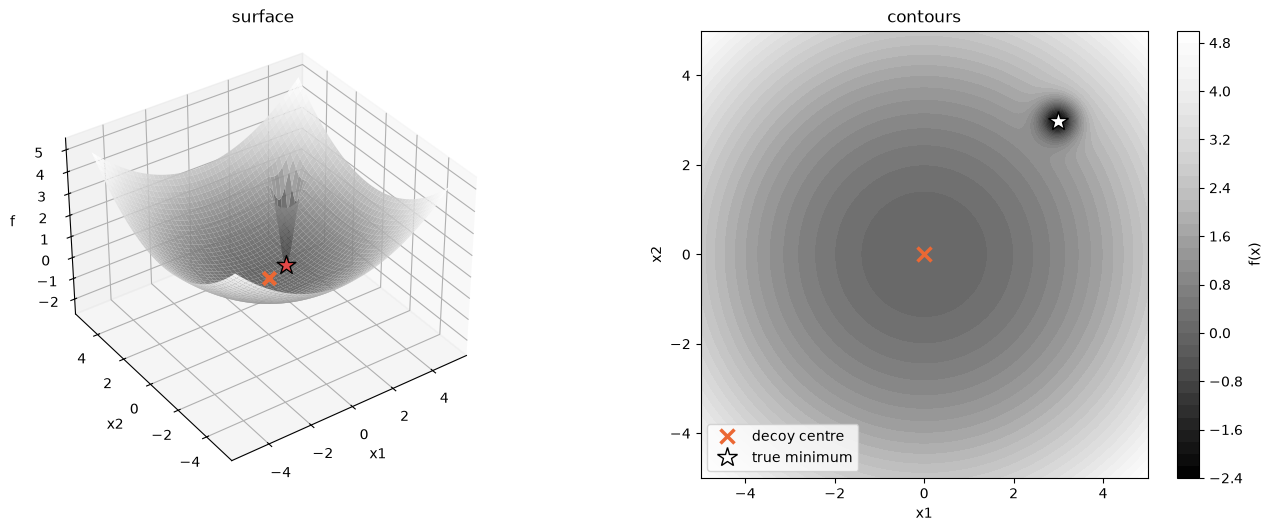

true minimum x* = [2.987 2.987], f* = -2.208; decoy minimum f = -0.000; epsilon = 0.05


In [4]:
report.landscape_figure(M)

*Next: what happens when the two default optimisers meet this landscape.*

## 3. Failure: the Exp 0 baselines

First three **illustrations** of single runs (they show what a run looks like and prove nothing about rates), then the aggregate over seeds.

**CMA-ES, seed 1000.** Samples coloured by generation (light = early), the diamond is the start, red ellipses are the 1-sigma search distribution at a few generations, and the right panel is sigma per generation. The path is re-run from the same seed and checked against the saved CSV (a warning appears on the figure if they differ).

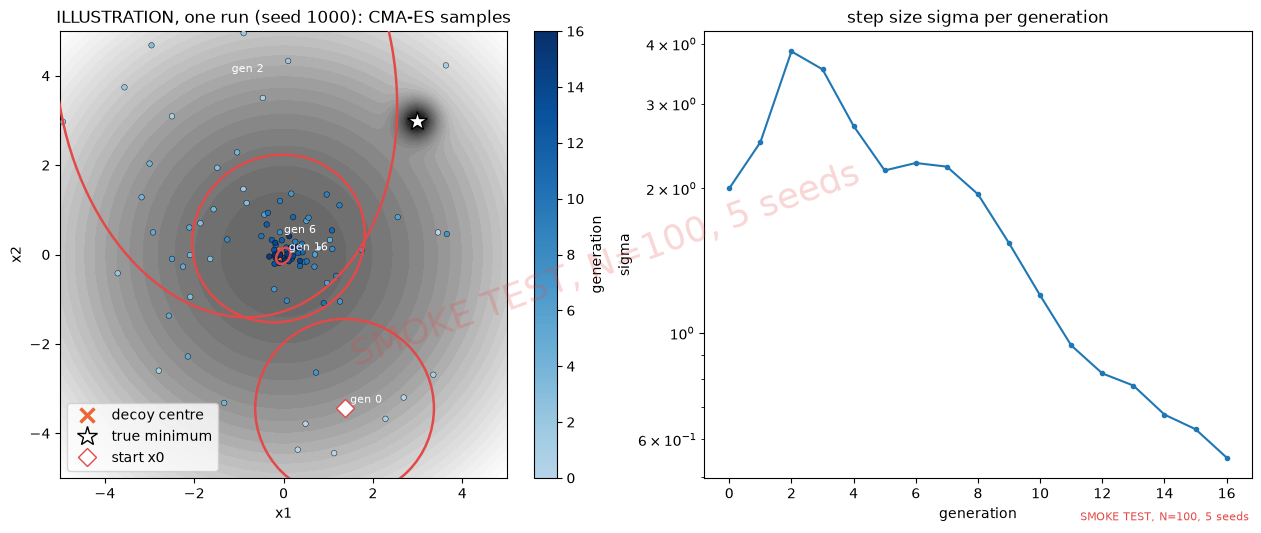

best regret = 2.209; final sigma = 0.5500; re-run vs saved CSV max |dx| = 4.4e-16


In [5]:
report.cmaes_illustration(M)

**BO, seed 1000.** The 10 initial design points are white squares and later points are coloured by the order they were chosen.

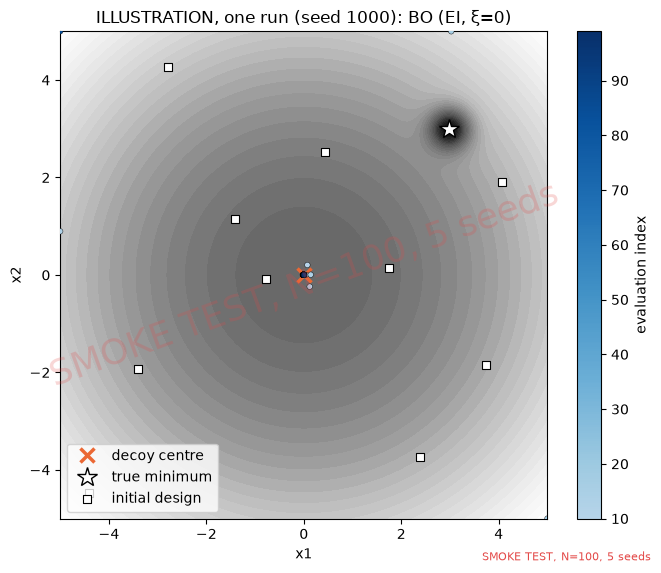

best regret = 2.208; final fitted lengthscales (domain units) = 20;20; well width w = 0.3


In [6]:
report.bo_illustration(M)

**Four seeds each (1000-1003).** The first four seeds of the fixed list, not picked for how they look. Top row CMA-ES, bottom row BO, colour = evaluation order.

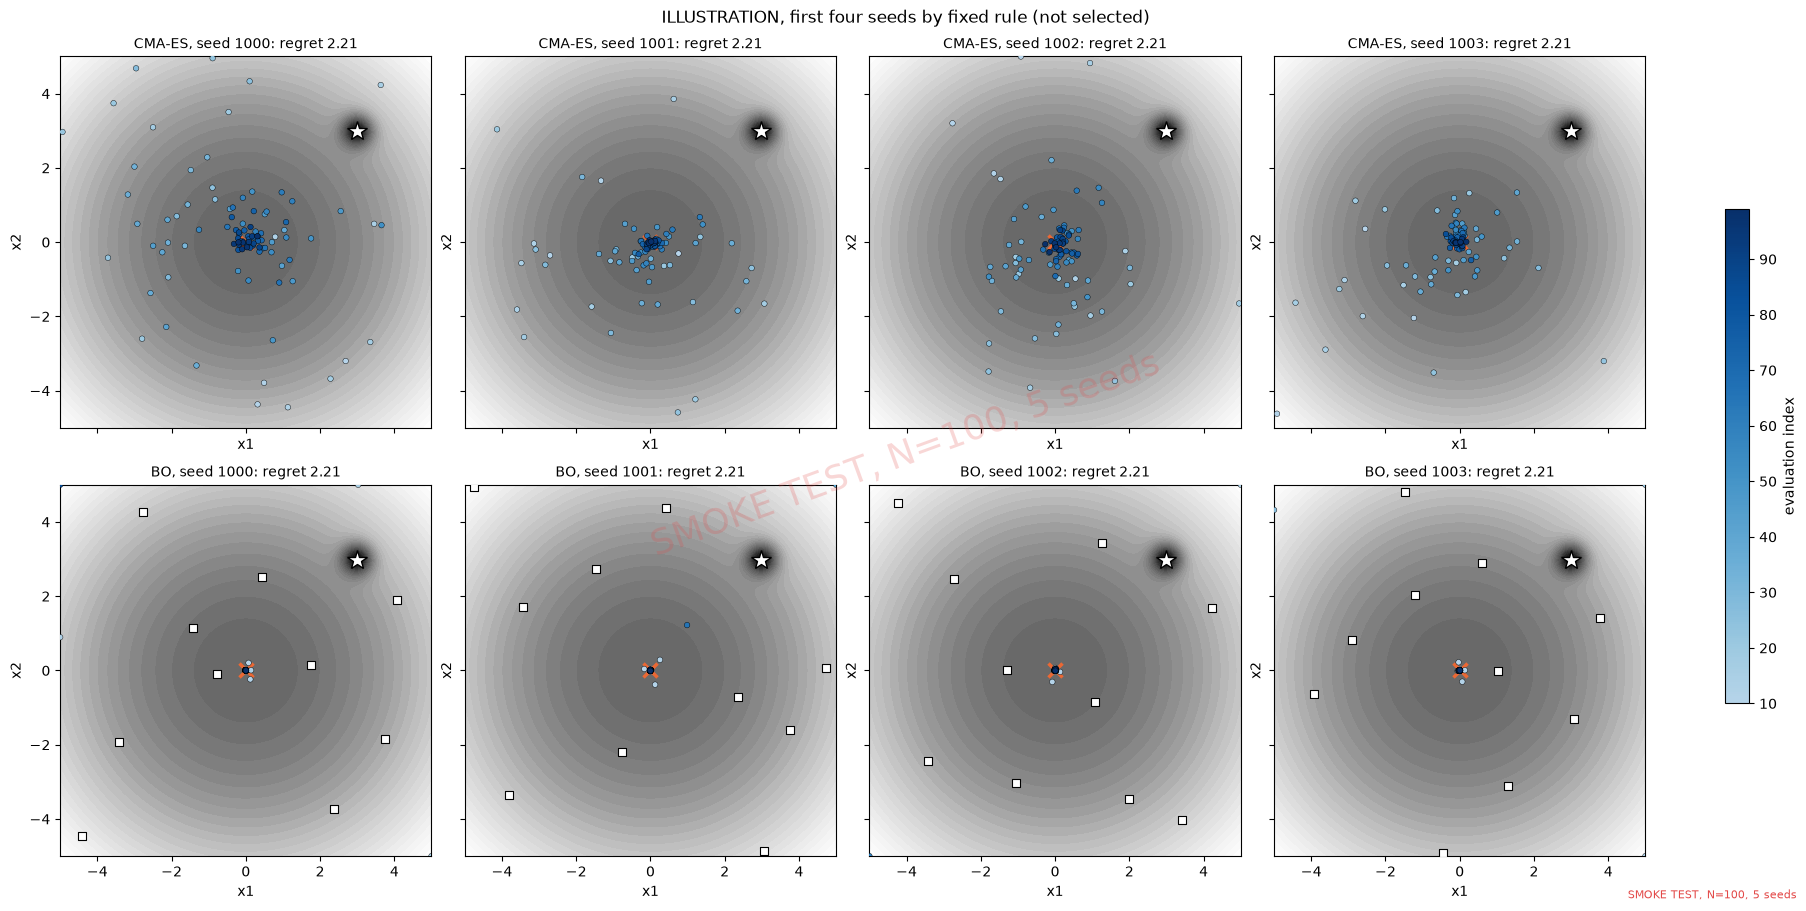

In [7]:
report.seed_grid(M)

**Aggregate over seeds.** Success rate with Wilson 95% intervals (left) and what happened to each run (right). Difference rows use a Newcombe interval, which is unpaired and so conservative when seeds are matched.

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H1 | Default CMA-ES gets stuck in a decoy basin | Low success, early sigma collapse, best point outside the global basin | High success, or sigma stays large |

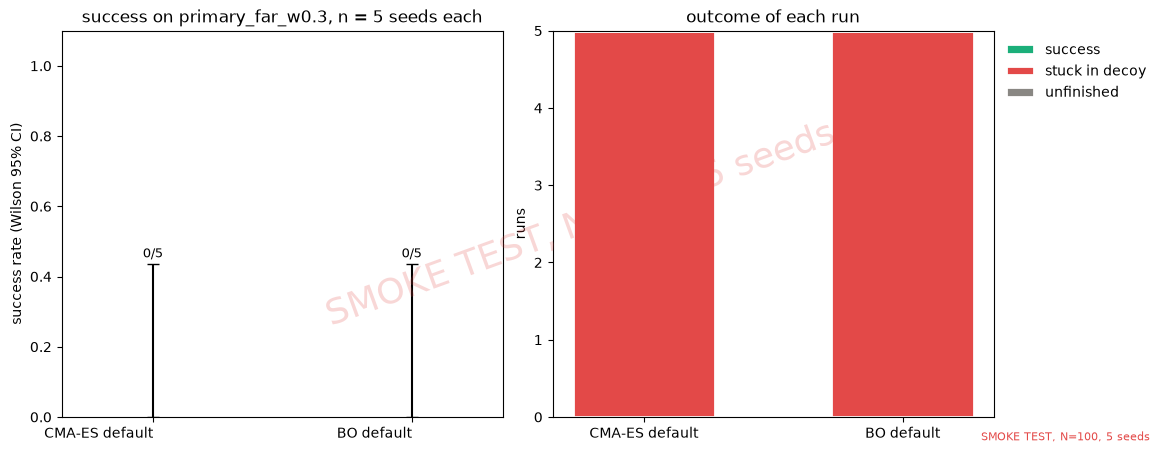

setting,success k/n,rate [Wilson 95%],diff vs default (λ=6) [Newcombe 95%],median regret,median generations,median restarts
default (λ=6),0/5,"0.00 [0.00, 0.43]",,2.21,17,0
EI ξ=0,0/5,"0.00 [0.00, 0.43]","+0.00 [-0.43, +0.43]",2.21,,


In [8]:
report.show_predictions(["H1"])
report.exp0_figure(M)

*The numbers below are from the saved full run (N = 300, 50 seeds, seeds 1000-1049; set `FAST = False` to see its figures). The FAST figures above are a smoke test.*

**Prediction H1** (shown above): default CMA-ES gets stuck in a decoy basin.

**Result (with CI and effect size).** On `primary_far_w0.3`, $\varepsilon = 0.05$, N = 300:

| method | success | Wilson 95% | stuck in decoy | unfinished | median regret |
| --- | --- | --- | --- | --- | --- |
| CMA-ES default | 0/50 | [0.000, 0.071] | 48 | 2 | 2.208 |
| BO default (EI, $\xi$ = 0) | 5/50 | [0.043, 0.214] | 45 | 0 | 2.208 |
| random sampling | 2/50 | [0.011, 0.135] | 11 | 37 | 1.114 |

Differences in success rate (Newcombe 95%, unpaired so conservative): BO minus CMA-ES +0.10 [+0.01, +0.21]; BO minus random +0.06 [-0.05, +0.18]; CMA-ES minus random -0.04 [-0.13, +0.04].

By the rule "claim a difference only when the intervals separate", **the three methods are not distinguishable from one another at 50 seeds, random sampling included**: all three Wilson intervals overlap pairwise. The BO minus CMA-ES interval only just excludes zero and is a weaker statement; it does not license ranking them. What the data do show is that none of the three usually succeeds: even BO's upper limit is 21%, about one run in five.

**H1.** On each of H1's "supported by" criteria the measurements fall on the supported side: low success (0/50); best point outside the global basin in 48 of 50 CMA-ES runs; sigma collapse (section 4). Nothing on the "contradicted by" side was seen (success is not high and sigma does not stay large). The pre-registration does not define "early" collapse, so section 4 reports the numbers and the reading is left to you. The status in `docs/scoreboard.csv` is yours to set.

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* the decoy bowl slopes toward its centre from everywhere, so a CMA-ES run that does not sample the well in its first generations has no signal pointing at it; the search distribution then contracts on the decoy. The two "unfinished" runs fit this picture: an early sample (generation 0 and generation 6) landed on the well's flank, yet sigma still collapsed onto the decoy.
- *Hypothesis:* BO and random sampling succeed mainly when a space-filling sample happens to land in the well. Of BO's five successes, three first entered the well within the 10-point initial design (evaluations 5, 5 and 9), one at evaluation 20 and one at evaluation 115. Measured, not tested: in the 45 failures no sample ever entered the well.

**Caveat.** One landscape (well width 0.3, far well) and one $\varepsilon$; 50 seeds leaves wide intervals, so small differences are unresolved. The settings are frozen ($\sigma_0 = 2$, start $U[-4,4]^2$, BO with 10 initial points, EI with $\xi = 0$, lengthscale bound 20) and results may depend on them. BO reproduces in distribution, not bit for bit, so the exact count 5/50 could shift on a re-run. "Unfinished" means the best point lies in the well's basin, not that the run was converging there (random sampling's 37 are best points on the well's flank).

*Next: the diagnostics that say why the baselines behave this way.*

## 4. Why: diagnostics

Two measured quantities, one per method. The mechanisms behind them are **hypotheses** until tested.

**CMA-ES step size.** Sigma per generation for every seed. *Hypothesis (from `docs/direction.md` section 2, not tested here):* inside a basin consecutive steps are anticorrelated, cumulative step-size adaptation shrinks sigma, and the search contracts and cannot leave. Measured: sigma, and where the best point ends up (section 3 outcomes). H1 is supported only by low success together with early sigma collapse and a best point outside the global basin.

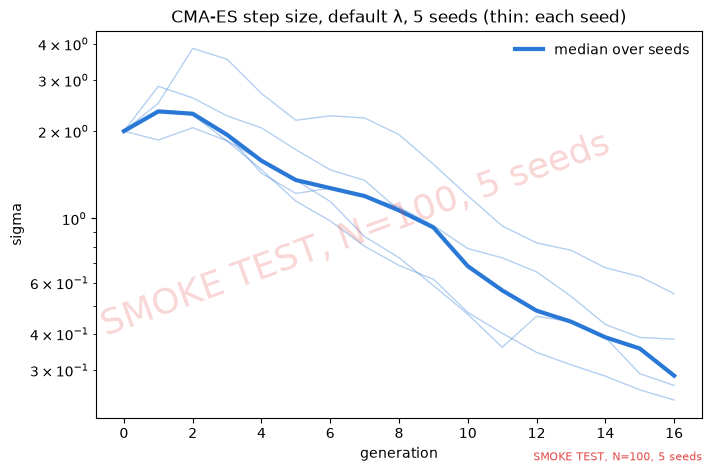

In [9]:
report.sigma_figure(M)

**BO fitted lengthscale versus the well width $w$.** Left: the smallest fitted lengthscale along a run on the primary landscape, against $w$ and the fitting upper bound. Right: its final value against $w$ across the far-well widths. *Hypothesis (not tested here):* when the lengthscale is much longer than $w$ the GP smooths over the well, gives it low uncertainty, and EI never samples it. Measured: the lengthscale and whether samples stay spread out; a causal claim would need a test that changes the lengthscale and nothing else. A lengthscale pinned at the upper bound also reflects the bound chosen before the runs.

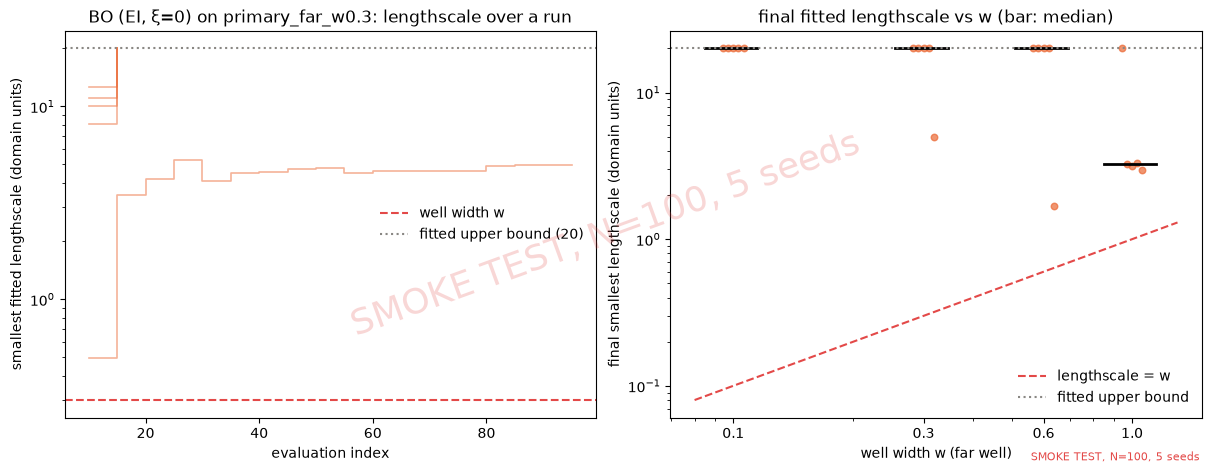

In [10]:
report.lengthscale_figure(M)

*The numbers below are from the saved full run (N = 300, 50 seeds); set `FAST = False` to see its figures.*

**Result (measured).**

- *CMA-ES step size.* Sigma starts at 2, rises above it in the first generations (median peak 2.24), then decays steadily in every run. It first falls below 0.2 (a tenth of the start value) at generation 19 (median; range 14-31) of 50, and below 0.02 at generation 35 (range 29-49). Median final sigma is 0.0025. From evaluation 100 on, at least 97.5% of every run's samples lie within 0.5 of the decoy centre, and the closest any CMA-ES sample comes to the well centre is 1.4 (median over runs).
- *BO lengthscale.* In 42 of 50 runs the smallest fitted lengthscale reaches the upper bound (20, twice the domain width), first at evaluation 15 (median; range 15-130), and it ends there. None of those 42 succeeded. Five of the other eight runs succeeded: their final lengthscale is 0.05-0.98, i.e. 0.17 to 3.3 times the well width $w = 0.3$.
- *BO sampling.* In the 45 failures no sample ever entered the well (closest approach 1.41, median), and about 99% of evaluations from 100 on are within 0.5 of the decoy centre. All 5 runs that did put a sample inside the well reached $\varepsilon$.

**Explanation** (hypotheses, not tested here):

- *CMA-ES hypothesis (from `docs/direction.md` section 2):* cumulative step-size adaptation shrinks sigma when consecutive steps are anticorrelated, as they are inside a basin, so the search contracts and cannot leave. The steady geometric decay in all 50 runs is consistent with this; no run held sigma fixed, so the mechanism itself is untested. Whether collapse is "early" is a reading of the numbers above (in the median run sigma is below 0.2 after 38% of the generations and below 0.02 after 70%), not a pre-registered threshold.
- *BO hypothesis A:* a lengthscale much longer than $w$ makes the surrogate smooth over the well, so EI never samples it.
- *BO hypothesis B (the reverse direction):* a run that has not yet sampled the well only ever sees the smooth bowl, so maximum likelihood picks a long lengthscale; the long lengthscale is then a symptom of missing the well, not its cause. The data cannot separate A from B: runs with a long lengthscale are exactly the runs without a well sample.
- *What would test them:* changing the lengthscale (for example capping it) while holding everything else fixed, or raising exploration ($\xi$, $\beta$) and checking whether samples reach the well; the latter is Exp 4.

**Caveat.** Where the lengthscale sits at the bound, the likelihood wanted a longer value than the frozen bound allows, so "at the bound" is partly a property of the bound. The BO split (all 5 runs with a well sample succeeded, none of the 45 others sampled it) says discovery, not refinement, is where BO fails here, but with 5 successes it is a description of this baseline, not an estimate of a rate. BO is reproducible in distribution only.

*Next: one factor at a time, to see which design choices change these failures.*

## 5. Experiment cards

One factor changes per experiment; every variant uses the same N and the same seeds. Each card has the same five parts: the pre-registered **prediction** (read from `docs/predictions.md`, unedited), a **figure** (success rate with Wilson 95% interval, same style as section 3, plus a table with the difference against the baseline), the **result** with CI and effect size, the **explanation**, and the **caveat**. A card's result and explanation are filled in only when its full results exist.

## CMA-ES block: Exps 1 to 3

Three CMA-ES design choices, one factor at a time: population size, restarts, then the initial step size that Exps 1 and 2 point to.

### Exp 1: population size $\lambda$ (1x, 2x, 4x default: 6, 12, 24)

Produce results: `python run_experiments.py --full --exp exp1 && python run_experiments.py --aggregate`

Also report generations completed per $\lambda$ (the table shows the median).

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H2 | Larger lambda raises success, with a sweet spot at fixed N | Success vs lambda rises, then plateaus or falls | Monotone decline, or no change |
| M1 | On the needle (primary) landscape, larger lambda helps only through extra early samples: the bowl slopes toward the decoy, so there is no global trend for selection averaging to follow | Any lambda gain is explained by the chance that a first-generation sample lands in the global basin (best point found in an early generation; gain tracks number of early samples) | Successful large-lambda runs find the well in later generations after the mean has moved toward it |

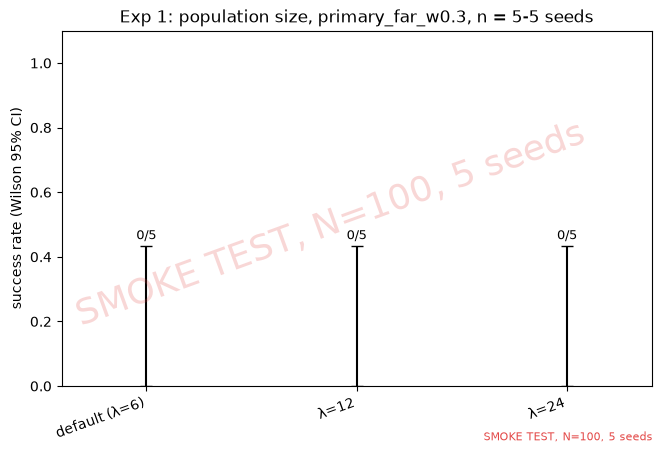

setting,success k/n,rate [Wilson 95%],diff vs default (λ=6) [Newcombe 95%],median regret,median generations,median restarts
default (λ=6),0/5,"0.00 [0.00, 0.43]",,2.21,17,0
λ=12,0/5,"0.00 [0.00, 0.43]","+0.00 [-0.43, +0.43]",2.21,9,0
λ=24,0/5,"0.00 [0.00, 0.43]","+0.00 [-0.43, +0.43]",1.88,5,0


In [11]:
report.show_predictions(['H2', 'M1'])
report.experiment_card("exp1", M)

*Full run: N = 300, 50 seeds (1000-1049), `primary_far_w0.3`, $\varepsilon = 0.05$. Set `FAST = False` to see the figure.*

**Result (with CI and effect size).**

| setting | success | Wilson 95% | samples ever inside the well ($d < w$) | best point in the well's basin | median generations |
| --- | --- | --- | --- | --- | --- |
| default ($\lambda$ = 6) | 0/50 | [0.000, 0.071] | 1 | 2 | 50 |
| $\lambda$ = 12 | 0/50 | [0.000, 0.071] | 7 | 7 | 25 |
| $\lambda$ = 24 | 0/50 | [0.000, 0.071] | 13 | 16 | 13 |

Success is 0/50 at every $\lambda$, so the differences in success are exactly zero and the intervals coincide. What does change with $\lambda$ is how often the search touches the well: 1, 7 and 13 of 50 runs put at least one sample inside it, and the median closest approach to the well centre falls from 1.40 to 1.03 to 0.65. Every first well sample came in generation 6 or earlier (generation 4 or earlier at $\lambda = 24$), and a run that entered the well had one to three samples in it in total. No run that entered went on to reach $\varepsilon$.

**H2** (larger $\lambda$ raises success, with a sweet spot): on success itself the data fall on the "contradicted by" side (no change). The statuses in `docs/scoreboard.csv` are yours to set. **M1** (any $\lambda$ gain comes only from extra early samples): the one quantity that rises with $\lambda$, well entry, happens in the first few generations, which is the pattern M1 describes. Neither status is set here.

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* a larger population draws more samples before the search distribution contracts (24 in generation 0 against 6), so it is likelier to drop one in a well that is 0.3 wide in a box 10 wide. This is extra coverage, not selection averaging, because the bowl slopes toward the decoy and there is no global trend toward the well to follow.
- *Hypothesis:* touching the well is not enough. With $\sigma_0 = 2$ against $w = 0.3$, one or two good samples among 6 to 24 weigh little in the update against the many samples near the decoy, so the mean keeps moving to the decoy and the well sample is never refined. The engine itself is not at fault in general (the sphere sanity check solved 20/20), but this particular mechanism is untested; Exp 2 (restarts) and the $\sigma$ traces are where to look.

**Caveat.** A floor of 0/50 cannot rank the settings on success; the well-entry counts are descriptive (1, 7, 13 are small counts) and were not pre-registered as a metric. One landscape, one $\varepsilon$, frozen $\sigma_0 = 2$ and start region. At $\lambda = 24$ a run completes only 13 generations, so any longer-run benefit would be cut off by the fixed budget.

#### Exp 1 side check: is $\lambda$ = 24 simply cut off by the budget?

**Why this was added.** Exp 1 gave 0/50 at every $\lambda$ at N = 300. At the end of those runs $\lambda$ = 6 and 12 had already contracted (median final $\sigma$ 0.0025 and 0.076), so more evaluations could not help them. $\lambda$ = 24 had not (median final $\sigma$ = 1.13 after only 13 generations), so its 0/50 could mean either "cannot succeed" or "ran out of budget before it could". To tell these apart we repeat the same three settings, on the same seeds, with five times the budget (N = 1500). This was decided before it ran (`docs/pilot_log.md`), with one extra budget only.

**How it is kept honest.** It is a side check, not part of any CMA-ES vs BO comparison: N = 1500 results live in `results/summary_long/`, are never drawn on BO axes, and no BO run is compared to them. The main comparisons use N = 300 throughout, because that is the budget every method is held to.

Run it with `python run_experiments.py --long --exp exp1_long && python run_experiments.py --aggregate --long`.

In [12]:
report.long_budget_card(M)

> **Not run yet: Exp 1 side check (N = 1500).** The side check has no smoke-test version; set `FAST = False` in the top cell to see its saved full results.  
> Run: `python run_experiments.py --long --exp exp1_long && python run_experiments.py --aggregate --long`

**Result.** Success is 0/50 at every $\lambda$ even with five times the budget. The number of runs whose best point lies in the well's basin is also unchanged (2, 7 and 16 of 50): the extra 1200 evaluations found the well in no new run. By the end $\lambda$ = 24 has contracted as well (median final $\sigma$ 0.0034, after a median 63 generations).

**What it shows.** The 0/50 at N = 300 is not a budget effect. The searches that did not touch the well early did not find it later, and the ones that touched it did not refine it. This matches the picture from Exp 0 and Exp 1 that CMA-ES here is decided in the first few generations (extra early samples, hypothesis M1), not by running longer. It also means a bigger $\lambda$ cannot be rescued by a bigger budget on this landscape.

**Caveat.** One extra budget (5x), one landscape, one $\varepsilon$. A much longer budget was not tried, and by design it would not be comparable to BO at N = 300 anyway.

### Exp 2: restarts (none, IPOP, BIPOP; total budget fixed at N)

Produce results: `python run_experiments.py --full --exp exp2 && python run_experiments.py --aggregate`

Restart triggers are frozen at tolx = 3e-3, tolfun = 1e-5. **Must report** restart firing rate per $\lambda$ (pilot, no-restart runs: 100% at $\lambda$ = 6, 84% at 12, 0% at 24). At $\lambda$ = 24 restarts never fire, so IPOP/BIPOP started there equal no restarts.

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H3 | Restarts beat a larger lambda at equal total budget | Higher success at the same N | Equal or lower success |
| M2 | On the needle landscape, restarts act like random search: each restart succeeds roughly when its fresh start (x0, sigma0) lands near the well | Success rate of IPOP/BIPOP close to what independent restarts from uniform x0 predict; successful restart index is spread out rather than concentrated on large-lambda restarts | Success concentrated in large-lambda restarts beyond what the restart count explains |

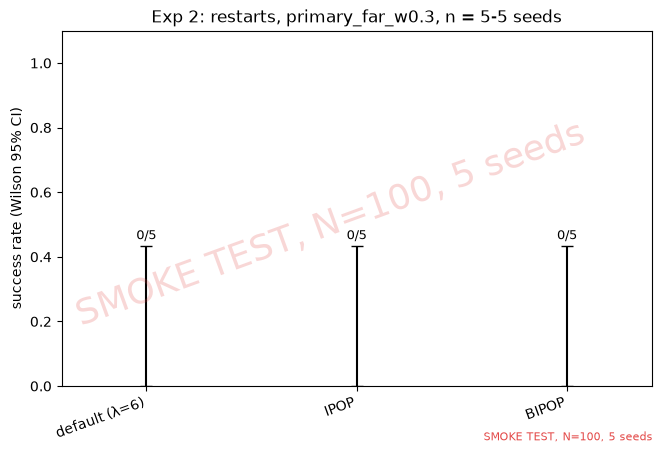

setting,success k/n,rate [Wilson 95%],diff vs default (λ=6) [Newcombe 95%],median regret,median generations,median restarts
default (λ=6),0/5,"0.00 [0.00, 0.43]",,2.21,17,0
IPOP,0/5,"0.00 [0.00, 0.43]","+0.00 [-0.43, +0.43]",2.21,17,0
BIPOP,0/5,"0.00 [0.00, 0.43]","+0.00 [-0.43, +0.43]",2.21,17,0


In [13]:
report.show_predictions(['H3', 'M2'])
report.experiment_card("exp2", M)

*Full run: N = 300, 50 seeds (1000-1049), `primary_far_w0.3`, $\varepsilon = 0.05$. Set `FAST = False` to see the figure.*

**Result (with CI and effect size).**

| setting | success | Wilson 95% | runs with a sample in the well ($d < w$) | best point in well basin | restarts per run |
| --- | --- | --- | --- | --- | --- |
| no restarts (default) | 0/50 | [0.000, 0.071] | 1 | 2 | 0 |
| IPOP | 0/50 | [0.000, 0.071] | 6 | 9 | 1 (every run) |
| BIPOP | 0/50 | [0.000, 0.071] | 6 | 9 | 1 (every run) |

Success is 0/50 for all three, so the differences are exactly zero. Restarts did raise how often the search touched the well, from 1 to 6 of 50 runs, but none reached $\varepsilon$. Five of the six well entries came from the restart ($\lambda$ = 12, started at a fresh $x_0 \sim U[-5,5]^2$); the sixth is the seed whose first start had already entered in Exp 0 and Exp 1.

**IPOP and BIPOP are the same here, by construction, not by accident.** All 50 BIPOP runs are identical to the IPOP runs, evaluation by evaluation. BIPOP's first restart is always the large-population regime, which is IPOP's first doubling, and both use the same restart random stream. At N = 300 each run has only one restart: the first (default) start spends a median 186 of the 300 evaluations before its stopping rule fires (range 144-234), so the restart gets the remaining 114, enough for about nine generations at $\lambda$ = 12 and never enough to converge and trigger a second one. The two variants could only differ if a second restart were possible. This is a property of the fixed budget, not a bug (the restart bookkeeping is in `code/optimizers.py`), and it means Exp 2 cannot say anything about IPOP versus BIPOP at this N.

**H3** (restarts beat a larger $\lambda$ at equal budget): restarts reached 0/50, as did $\lambda$ = 12 and $\lambda$ = 24 in Exp 1, so on success the data fall on the "contradicted by" side (equal success). **M2** (a restart acts like random search: success close to what independent fresh starts predict): the first clause is the one this run can speak to. A fresh $\lambda$ = 12 start touched the well in 7 of 50 runs in Exp 1 (300 evaluations) and the restart touched it in 5 of 50 (114 evaluations), which is the same order, so restarts look like fresh starts in how they find the well. The second clause (which restart succeeded) cannot be assessed, because nothing succeeded. Neither status is set here; `docs/scoreboard.csv` is yours.

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* restarts help find the well only as much as extra independent draws do, which is the M1 story again (coverage), and once the well is touched the same problem as in Exp 1 applies: $\sigma_0 = 2$ is large against $w = 0.3$, so the touch is not refined.
- *Hypothesis:* a restart that is expensive in evaluations (the default start takes about 186 of them) buys very little breadth at N = 300, so any restart advantage would need a smaller budget share for the first start.

**Caveat.** One landscape, one $\varepsilon$, frozen restart triggers (tolx = 3e-3, tolfun = 1e-5) and frozen $\sigma_0$. With a floor of 0/50 success cannot rank the settings; the well-entry counts (1, 6, 6) are small and were not pre-registered as a metric. The restart triggers were chosen from firing rates only, so they were not tuned to this outcome.

### What Exps 1 and 2 tell us, and why the initial step size and the well width matter

Exps 0, 1 and 2 (and the N = 1500 side check) all gave 0/50 for CMA-ES. Three measured facts, and one explanation to test.

**Measured.**

- More samples early help *find* the well: runs with a sample inside it went from 1/50 (λ = 6) to 7/50 (λ = 12) to 13/50 (λ = 24), always in the first few generations, and restarts raised it from 1/50 to 6/50.
- None of those runs reached ε. Finding the well did not turn into success, and extra budget did not either (N = 1500: still 0/50 and no new well found).
- The success criterion is reachable and the code works: in a positive control on *pilot* seeds (9000-9019, `pilot/cma_positive_control.py`, run after Exps 0-2 so it is post hoc), CMA-ES started at the well centre succeeded 20/20 with σ₀ = 0.3 and 17/20 with σ₀ = 0.5 from 1.0 away, but only 0/20 with the frozen σ₀ = 2, even when started exactly at the well.

**Explanation (hypothesis, tested next).** Success needs a point within about 0.05 of the well centre, and the well has width w = 0.3. With σ₀ = 2, about 7 times w, the early samples are spread so widely that the decoy bowl, which slopes toward its centre from everywhere, supplies most of the selected points. The update then moves the mean toward the decoy and σ contracts there, even if one sample landed in the well. In this picture λ and restarts cannot fix the failure because they change how often the well is *touched*, not whether it is *refined*, and the quantity that sets refinement is the ratio σ₀ / w.

**What is tested, in order.**

1. **Exp 3** changes σ₀ and nothing else, in two arms. A *random-start* arm (the baseline start) asks whether any σ₀ helps in practice (CMA2). An *oracle-start* arm, started 1.0 from the well, removes the finding problem to ask whether σ₀ alone sets refinement (CMA1). The oracle arm uses knowledge of the well, so it is a diagnostic of the mechanism and is never compared with BO.
2. **Exp 8** changes the well width w with σ₀ fixed. If the ratio σ₀ / w is what matters, CMA-ES success should rise as w grows toward σ₀ (CMA3).

If CMA1 holds the explanation is supported for the refinement step; if CMA2 also holds, no single σ₀ solves the problem from a random start, because a small σ₀ rarely reaches the well. Either way the current findings stand as measured.

### Exp 3: CMA-ES initial step size σ₀ (0.3, 0.5, 1, 2 default, 4)

Produce results: `python run_experiments.py --full --exp exp3 && python run_experiments.py --full --exp exp3_oracle && python run_experiments.py --aggregate`

Only σ₀ changes; λ is the default, there are no restarts, N = 300, seeds 1000-1049, `primary_far_w0.3`, ε = 0.05. **Random start** (the baseline U[-4,4]²) is the fair comparison. **Oracle start** (1.0 from the well centre, random direction) uses knowledge of the well, is a diagnostic only, and is not compared with BO. Prediction text is in `docs/predictions_addendum.md`.

In [14]:
report.show_predictions(['CMA2'])
report.experiment_card("exp3", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| CMA2 | From the baseline random start (U[-4,4]^2) no sigma0 gives high success: a small sigma0 rarely reaches the well (finding fails) and a large sigma0 cannot refine it. Every sigma0 arm stays below 12/50 successes (below the point where its Wilson interval lies wholly above random sampling's) | All five arms have fewer than 12/50 successes | At least one arm has 12/50 or more |

> **Not run yet: Exp 3: CMA-ES initial step size (random start).** 4 of its settings have no saved runs (e.g. σ0=0.3 on primary_far_w0.3, σ0=0.5 on primary_far_w0.3, σ0=1 on primary_far_w0.3 ...).  
> Run: `python run_experiments.py --fast --exp exp3 && python run_experiments.py --aggregate --fast`

*Full run: N = 300, 50 seeds (1000-1049), `primary_far_w0.3`, $\varepsilon = 0.05$, baseline random start $U[-4,4]^2$. Set `FAST = False` to see the figure.*

**Result (with CI and effect size).**

| $\sigma_0$ | success | Wilson 95% | runs with a sample in the well ($d < w$) | median closest approach to the well centre |
| --- | --- | --- | --- | --- |
| 0.3 | 0/50 | [0.000, 0.071] | 0 | 2.26 |
| 0.5 | 0/50 | [0.000, 0.071] | 0 | 2.09 |
| 1 | 1/50 | [0.004, 0.105] | 2 | 2.16 |
| 2 (default) | 0/50 | [0.000, 0.071] | 1 | 1.40 |
| 4 | 0/50 | [0.000, 0.071] | 4 | 0.93 |

No $\sigma_0$ changes success: 0 or 1 of 50 everywhere, every difference from the default is within about $\pm 0.1$ and every interval overlaps. What does change is how close the search gets to the well. A small $\sigma_0$ never touches it (0/50 runs at 0.3 and 0.5, closest approach about 2), because a tight cloud started at random settles on the nearest bowl; a large $\sigma_0$ touches it more often (4/50 at $\sigma_0 = 4$) and gets within 0.93 of its centre on median.

**CMA2** (no $\sigma_0$ gives high success from a random start; every arm stays below 12/50): the largest count is 1/50, so the measurements fall on the supported side. The status in `docs/scoreboard.csv` is yours.

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* from a random start the two requirements pull $\sigma_0$ in opposite directions. Reaching the well needs breadth (large $\sigma_0$, more samples), and refining it needs a $\sigma_0$ comparable to $w$. The data show each half separately (well entry rises with $\sigma_0$; the oracle arm below shows refinement falls with it) but no value does both.
- *Hypothesis:* a small $\sigma_0$ makes CMA-ES a local search from its random start, so it succeeds only if the start is already near the well, which essentially never happens (the well covers about 0.3% of the box).

**Caveat.** One landscape, one $\varepsilon$, one start distribution, one grid of five values; a value between 0.3 and 1 combined with a larger $\lambda$ was not tried (that is a different factor combination). With counts of 0 and 1 the arms cannot be ranked on success.

**Oracle-start arm** (mechanism test; started 1.0 from the well centre).

In [15]:
report.show_predictions(['CMA1'])
report.experiment_card("exp3_oracle", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| CMA1 | CMA-ES fails to refine once it is near the well because sigma0 is too large relative to the well width w, not because it cannot find the well. Started 1.0 from the well (oracle start), success falls as sigma0 grows: high at sigma0 = 0.3 and 0.5, near zero at sigma0 = 2 and 4 | Wilson interval of sigma0 = 0.3 lies above that of sigma0 = 2, and success does not rise with sigma0 | The sigma0 = 0.3 and sigma0 = 2 intervals overlap |

> **Not run yet: Exp 3: CMA-ES initial step size (oracle start 1.0 from the well).** 5 of its settings have no saved runs (e.g. oracle σ0=0.3 on primary_far_w0.3, oracle σ0=0.5 on primary_far_w0.3, oracle σ0=1 on primary_far_w0.3 ...).  
> Run: `python run_experiments.py --fast --exp exp3_oracle && python run_experiments.py --aggregate --fast`

*Full run: N = 300, 50 seeds (1000-1049), `primary_far_w0.3`, $\varepsilon = 0.05$. The first start is 1.0 from the well centre in a random direction (oracle start: it uses knowledge of the well, so this is a diagnostic of refinement, not a method comparison, and no BO run is compared with it). Set `FAST = False` to see the figure.*

**Result (with CI and effect size).**

| $\sigma_0$ | success | Wilson 95% | difference vs $\sigma_0 = 2$ (Newcombe 95%) | runs with a sample in the well |
| --- | --- | --- | --- | --- |
| 0.3 | 33/50 | [0.522, 0.776] | +0.62 [+0.45, +0.74] | 35 |
| 0.5 | 31/50 | [0.482, 0.741] | +0.58 [+0.41, +0.70] | 39 |
| 1 | 10/50 | [0.112, 0.330] | +0.16 [+0.03, +0.29] | 23 |
| 2 | 2/50 | [0.011, 0.135] | (baseline) | 11 |
| 4 | 1/50 | [0.004, 0.105] | -0.02 [-0.12, +0.07] | 11 |

Success falls steadily as $\sigma_0$ grows, 33, 31, 10, 2, 1 of 50, and the intervals at $\sigma_0 = 0.3$ and $\sigma_0 = 2$ do not overlap (difference +0.62, interval excluding zero by a wide margin). Starting from 1.0 away, the same CMA-ES that scored 0/50 from a random start succeeds in two thirds of runs when $\sigma_0$ is 0.3.

**CMA1** (started near the well, success falls as $\sigma_0$ grows; the $\sigma_0 = 0.3$ interval above the $\sigma_0 = 2$ interval): the measurements fall on the supported side. This is the same direction as the pilot positive control (pilot seeds, post hoc), now on the experiment seeds. The status in `docs/scoreboard.csv` is yours.

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* with $\sigma_0 = 0.3$ (equal to $w$) the first samples are already inside or next to the well, the ranking points into it, and $\sigma$ contracts on it. With $\sigma_0 \ge 2$ most samples are decoy points that outrank nothing in the well, the bowl dominates the update, and the mean drifts to the decoy. The step size relative to $w$, not the distance to the well, decides which happens.
- Not every near-well run succeeds even at $\sigma_0 = 0.3$ (33 of 50, 35 of 50 touch the well): starting 1.0 away with a tight cloud, some runs do not reach it before contracting. That is the mirror of the random-start result: too small a $\sigma_0$ fails to find, too large fails to refine.

**Caveat.** This isolates refinement by giving CMA-ES an unfair start, so it shows what $\sigma_0$ does once the well is near, not what a user could achieve. One distance (1.0) and one landscape; the mechanism is shown by the dependence on $\sigma_0$, not proved: a direct check would track $\sigma$ and the mean per generation, which was not done. Exp 8 (width sweep) tests the same ratio from the other side.

#### Exp 3 follow-up A: where does the search mean go? (CMA4)

No new runs: the five oracle configs are re-run on seeds 1000-1049 (CMA-ES is deterministic given the seed) to read off, each generation, the distance of the search distribution's mean to the well centre. Command: `python run_experiments.py --trace`. This turns "success falls as $\sigma_0$ grows" into a direct look at the mechanism.

In [16]:
report.show_predictions(['CMA4'])
report.mean_trace_figure(M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| CMA4 | The refinement mechanism is visible in the search distribution's mean. In the oracle arm with sigma0 = 0.3 the mean ends within w of the well in at least 60% of runs; with sigma0 = 2 it ends within w in at most 15% of runs, and in the sigma0 = 2 runs that touched the well (a sample with d < w) the mean ends closer to the decoy centre than to the well in more than half of them | Both conditions hold | The sigma0 = 2 share within w exceeds 15%, or in the touched sigma0 = 2 runs the mean ends closer to the well in at least half; or the sigma0 = 0.3 share is below 60% |

> **Not run yet: Exp 3 mean trace (CMA4).** The mean trace has no smoke-test version; set `FAST = False` in the top cell to see its saved results.  
> Run: `python run_experiments.py --trace`

*Full results (50 seeds); set `FAST = False` to see the figure.*

**Result.** With $\sigma_0 = 0.3$ the mean walks into the well: its median distance falls from 1.0 at generation 0 to 0.29 at generation 5, 0.09 at generation 10 and 0.01 at generation 20. With $\sigma_0 = 2$ it walks away: the median distance rises to 4.12 by generation 5 and sits at 4.2 from then on, which is the distance from the well $(3,3)$ to the decoy centre at the origin (4.24).

| setting | final mean within $w$ of the well | runs that touched the well | touched runs whose final mean is closer to the decoy centre than to the well |
| --- | --- | --- | --- |
| oracle $\sigma_0 = 0.3$ | 33/50 | 35 | 2/35 |
| oracle $\sigma_0 = 2$ | 1/50 | 11 | 10/11 |

**CMA4** (at $\sigma_0 = 0.3$ at least 60% of runs end within $w$; at $\sigma_0 = 2$ at most 15%, and in the touched $\sigma_0 = 2$ runs the mean ends nearer the decoy in more than half): all three conditions are met (66%, 2%, 10 of 11), so the measurements fall on the supported side. The status in `docs/scoreboard.csv` is yours.

**What it shows.** In 10 of the 11 runs at $\sigma_0 = 2$ where a sample did land in the well, the mean still ended at the decoy. A well sample is not enough: with a wide cloud the other selected points sit on the bowl and pull the mean away, which is the mechanism proposed above, now observed and not only inferred from success rates.

**Caveat.** The mean is the centre of the search distribution, not the best point; the trace is for the oracle start, one distance (1.0), one landscape. The thresholds in CMA4 were set after seeing Exp 3's success counts (not the traces).

#### Exp 3 follow-up B: does only the ratio $\sigma_0 / w$ matter? (CMA5)

The explanation says refinement is set by the step size *relative to the well*. If so, the same ratio should give the same success at every well width. Oracle start at $(10/3)\,w$ from the well (1.0 at $w = 0.3$, as in the oracle arm), $\sigma_0 = k\,w$ with $k \in \{1, 3, 7, 20\}$, on $w \in \{0.1, 0.3, 0.6, 1.0\}$, 50 seeds, N = 300. Command: `python run_experiments.py --full --exp exp3_ratio && python run_experiments.py --aggregate`. A diagnostic: it uses the oracle start and is never compared with BO.

In [17]:
report.show_predictions(['CMA5'])
report.experiment_card("exp3_ratio", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| CMA5 | Refinement depends on the ratio sigma0 / w, not on sigma0 or w separately. With an oracle start at (10/3) w and sigma0 = k w, success falls with k at every width (k = 1 above k = 20 with non-overlapping Wilson intervals at each of w = 0.1, 0.3, 0.6, 1.0), and at k = 1 the four widths are not separated (all four Wilson intervals overlap pairwise) | Both conditions hold | k = 1 is not above k = 20 at some width, or at k = 1 two widths have non-overlapping intervals (success then depends on w itself, not only on the ratio) |

> **Not run yet: Exp 3: CMA-ES step size relative to well width (ratio test).** 16 of its settings have no saved runs (e.g. σ0=1w on primary_far_w0.1, σ0=1w on primary_far_w0.3, σ0=1w on primary_far_w0.6 ...).  
> Run: `python run_experiments.py --fast --exp exp3_ratio && python run_experiments.py --aggregate --fast`

*Full run: 50 seeds per cell (seeds 1000-1049), N = 300; set `FAST = False` to see the figure.*

**Result (Wilson 95% intervals above).** Success by $k = \sigma_0 / w$ and well width:

| $k$ | $w = 0.1$ | $w = 0.3$ | $w = 0.6$ | $w = 1.0$ |
| --- | --- | --- | --- | --- |
| 1 | 44/50 | 33/50 | 17/50 | 24/50 |
| 3 | 25/50 | 12/50 | 14/50 | 36/50 |
| 7 | 1/50 | 0/50 | 14/50 | 40/50 |
| 20 | 0/50 | 1/50 | 14/50 | 40/50 |

For the narrow wells ($w = 0.1, 0.3$) the pattern is Exp 3's: success collapses as $k$ grows (44 to 0, and 33 to 1). For the wide wells it does not. At $w = 0.6$ success is flat (17, 14, 14, 14) and at $w = 1.0$ it *rises* with $k$ (24 to 40).

**CMA5** had two conditions: success at $k = 1$ above $k = 20$ with non-overlapping intervals at every width, and the four widths not separated at $k = 1$. Both fail. At $w = 0.6$ the $k = 1$ and $k = 20$ intervals overlap ([0.22, 0.48] and [0.17, 0.42]); at $w = 1.0$ the order is reversed (24/50 against 40/50); and at $k = 1$ the intervals at $w = 0.1$ ([0.76, 0.94]) and $w = 0.6$ ([0.22, 0.48]) do not overlap. The measurements fall on the **contradicted** side. The status is yours to set.

**Check for a bug or slip (done before reading the result).** Several cells have identical counts (14, 14, 14 at $w = 0.6$; 40 and 40 at $w = 1.0$). The sample paths of $k = 7$ and $k = 20$ are in fact identical in all 50 seeds at $w = 0.6$ and at $w = 1.0$. This is a property of the `cma` library, not of our code: with bounds $[-5, 5]$ it caps the effective standard deviation (option `maxstd`, set from the bound range, about 4 here). Starting from the same point and seed, $\sigma_0 = 4, 5, 6, 7, 10, 20$ all draw exactly the same first samples, while $\sigma_0 = 3$ differs. So the labelled $k$ is not the effective ratio once $\sigma_0 > 4$: at $w = 0.6$ both $k = 7$ ($\sigma_0 = 4.2$) and $k = 20$ ($\sigma_0 = 12$) are effectively $\sigma_0 = 4$ (ratio 6.7); at $w = 1.0$ both are effectively 4 (ratio 4); the $k = 20$ arm at $w = 0.3$ ($\sigma_0 = 6$) is also effectively 4. Earlier experiments are not affected: Exps 1 and 2 use $\sigma_0 = 2$, Exp 3 reaches 4 at most (exactly at the cap), and Exp 3's oracle arm at $w = 0.3$ is unchanged. The logged $\sigma$ column shows the nominal value.

**What it shows (hypotheses, not tested).**

- Success is not a function of $\sigma_0 / w$ alone. For narrow wells a large $\sigma_0$ is fatal, as before; for wide wells it is not.
- *Hypothesis:* a wide well (at $w = 1.0$ the region below the decoy floor is about a tenth of the box) is found by a broad cloud and, being wide, has a funnel the cloud can follow, so refinement does not need a small $\sigma_0$. A small $\sigma_0$ at $w = 1.0$ starts 3.3 away and rarely reaches the well (finding fails), which is why $k = 1$ is the worst there. The decoy bowl has a fixed scale, so the well's size relative to the box and the bowl matters as well as the ratio.
- So the explanation needs refining: step size relative to the well matters when the well is small compared with the bowl and the box, and the width sweep (Exp 8) will show the same mixture from the other side.

**Caveat.** The effective-$\sigma$ cap means the high-$k$ arms at wide $w$ are not the ratios they are labelled with, and $k = 7$ and $k = 20$ are duplicates there; a cleaner ratio grid would stay at or below the cap ($\sigma_0 \le 4$) at every width. One oracle distance, one landscape, the same $\varepsilon$ at every width (it corresponds to roughly the same fraction of $w$, but the bowl does not scale).

## BO block: Exps 4, 5, 6 and 7

Four BO design questions, one factor at a time, each against the same `bo_default` baseline (EI with $\xi = 0$, Matern-5/2, 10 initial points, maximum-likelihood fit with the lengthscale in [0.05, 20] and fixed noise 1e-6): Exp 4 changes how much EI explores, Exp 5 changes the acquisition family, Exp 6 changes the fitting settings one at a time (lengthscale cap, noise level, learned noise, a lengthscale prior), Exp 7 changes the kernel. Exps 4 and 5 and the `bo_map` reference were run as one batch (`--exp exp4_5`, 2026-10-26) and split into separate experiments for reporting on 2026-10-28; no config, seed or run changed (see `docs/pilot_log.md`). Exp 6 then replaces the all-at-once `bo_map` as the test of the fitting recipe, and the kernels (Exp 7) come after it.


### Exp 4: BO explore/exploit inside EI ($\xi$)

Produce results: `python run_experiments.py --full --exp exp4_5 && python run_experiments.py --aggregate` (also produces Exp 5 and the `bo_map` reference of Exp 6)

EI is swept over $\xi \in \{0, 0.01, 0.1, 0.5, 1, 2\}$ (units of $f$; the well is about 2.2 deep, so large $\xi$ is close to pure exploration). Only $\xi$ changes. The initial design is fixed at 10 points for every arm.

Also report sample spread, the fitted lengthscale against $w$ (section 4) and the Cholesky jitter-fallback count.

**Link to Exp 0.** BO1 (post hoc, from Exp 0) says default BO fails at discovery; H4 tests whether more exploration fixes that; BO2 says any gain comes from discovery and not from a shorter lengthscale. Same shape as CMA-ES: H1, M1, H2. Prediction text is in `docs/predictions_addendum.md`.


In [18]:
report.show_predictions(['H4', 'BO1', 'BO2'])
report.experiment_card("exp4", M)
report.discovery_card("exp4", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H4 | BO finds the narrow basin at low d only if it explores enough | Success rises with xi or beta | Insensitive to xi and beta |
| BO1 | (post hoc, from Exp 0) Default BO fails at discovery, not refinement: it rarely samples the well, and while it has not sampled it the fitted lengthscale sits far above w | Runs with no well sample fail; runs that sampled the well reach epsilon; lengthscale before the first well sample is many times w | Runs that sampled the well still fail, or the pre-discovery lengthscale is comparable to w |
| BO2 | Exploration (xi, beta, Thompson) helps BO only by raising the chance that a sample lands in the well (discovery); it does not work by repairing the lengthscale. The fitted lengthscale before the first well sample stays long under every variant and shrinks only after a well sample | Success of a variant tracks the share of its runs with a well sample; pre-discovery lengthscale is as long as the baseline's in every variant | A variant raises success while its pre-discovery lengthscale is clearly shorter than the baseline's (exploration changes the surrogate itself) |

> **Not run yet: Exp 4: BO explore/exploit (EI xi).** 3 of its settings have no saved runs (e.g. EI ξ=0.5 on primary_far_w0.3, EI ξ=1 on primary_far_w0.3, EI ξ=2 on primary_far_w0.3).  
> Run: `python run_experiments.py --fast --exp exp4 && python run_experiments.py --aggregate --fast`

> **Not run yet: BO discovery table.** It has no smoke-test version; set `FAST = False` to see its saved results.  
> Run: `python run_experiments.py --discovery`

**Result (with CI and effect size):** at $N = 300$ over 50 seeds, success is 5/50 for $\xi = 0$, 8/50 at 0.01, **17/50 at 0.1**, 12/50 at 0.5, 5/50 at 1 and 3/50 at 2. Only $\xi = 0.1$ separates from the baseline: +0.24, Newcombe 95% interval [+0.08, +0.39]. $\xi = 0.5$ is +0.14 [−0.01, +0.29], and $\xi = 0.01$, 1 and 2 are indistinguishable from $\xi = 0$. The discovery table above shows what changed. With $\xi = 0$, 5 of 50 runs ever sample inside the well, and 3 of those are seeds where the 10 random initial points already land there (the same 10 points in every setting, since seeds are shared). For $\xi \ge 0.1$ the runs that sample inside the well rise to 40–45 of 50, almost always found by the search itself. But the first sample in the well comes late (median evaluation 116–156 of 300), only 2–4 samples land there (median), and success given a well sample falls as $\xi$ grows (17/45, 12/42, 5/40, 3/42).

**Explanation** (untested explanations are labelled *hypothesis*): *Measured:* every successful run sampled inside the well, so discovery is necessary; but it is not sufficient once $\xi \ge 0.5$. *Measured:* at $\xi \ge 0.1$ 34–41% of the samples after the initial design sit within 0.5 of the box edge (3% at $\xi = 0$). *Hypothesis (the part about the edges is tested in the next subsection):* the margin makes EI score only points predicted to beat the best value by at least $\xi$, so the GP's most uncertain places (the far corners and edges of the box) keep winning, which finds the well but then spends the remaining budget exploring the edges instead of refining the well. At $\xi = 2$, about the whole well depth (2.2), even a point in the well barely clears the margin. At small $\xi$ the opposite happens: EI exploits the decoy bowl and almost never leaves it. The best $\xi$ is the one between these two. *Link to H4:* H4 said success rises with $\xi$ or $\beta$. Here it rises from $\xi = 0$ to 0.1 and then falls, and (Exp 5) it does not move with $\beta$. *Link to BO2:* the fitted lengthscale before the first well sample is at its upper bound (20) in every setting, so exploration does not work by repairing the surrogate; but BO2's other part, that success tracks the share of runs with a well sample, holds only at the low end.

**Caveat:** one landscape, one well width, one $d$. The $\xi$ grid was fixed from the landscape before running, so the peak at 0.1 is one grid point wide and its exact position is not established (the grid has no value between 0.1 and 0.5). The Newcombe intervals are unpaired and conservative. The "touched the well" definition (a sample within $w$ of the well centre) is the CMA-ES one but was applied to BO after the results were seen, so the discovery table is exploratory. The edge-share and explanation are post hoc.


#### Exp 4 follow-up: why does success fall at large $\xi$? Found, but not refined

Exp 4 raised a question: $\xi \ge 0.1$ finds the well in about 90% of runs, yet success given a well sample falls as $\xi$ grows (17/45, 12/42, 5/40, 3/42). What do the runs do after they find the well? This uses only the saved Exp 4 runs (no new runs): `python run_experiments.py --discovery`. It covers the runs that find the well *by search* (first sample within $w$ of the well after the 10-point initial design). The "touched the well" definition was fixed after the Exp 4 results were seen, so this follow-up is **exploratory**.


In [19]:
report.xi_mechanism_figure(M)

> **Not run yet: Exp 4 mechanism figure.** It has no smoke-test version; set `FAST = False` to see its saved results.  
> Run: `python run_experiments.py --discovery`

**Result.**
- **A (when):** the share of runs that have sampled the well climbs steeply between evaluations 50 and 200 for $\xi \ge 0.1$ and ends at 80–90%. For $\xi = 0$, LCB and Thompson sampling it is flat from the initial design on (6–10%).
- **B (where the samples go, after the first well sample):** for $\xi = 0.1, 0.5, 1$ the share of samples at the box edge jumps from 0.19, 0.28, 0.31 to 0.65, 0.59, 0.54, and only 1–3% of the later samples land within $w$ of the well. For $\xi = 2$ the edge share is high before (0.34) and after (0.37): it never settles. LCB and Thompson sampling, in the one run each that finds the well by search, put 71–96% of the later samples within $w$ of it (a single run each, so this is an illustration, not a rate).
- **C (maps):** $\xi = 0$ samples almost only the bowl centre; $\xi = 0.1$ covers the box, with a ring along the edges and a dark spot on the well; $\xi = 2$ is spread nearly uniformly, with a ring at the edge and almost nothing on the well.
- **Successful vs failed runs** (among runs that found the well; table above): at $\xi = 0.1$, successful runs put a median of 5 samples in the well and failed runs 2. After the first well sample, failed runs put 77% of their samples at the edge, successful runs 40%. The first well sample is not later in failed runs (evaluation 160 vs 167), so it is not about running out of budget. The first well sample is shallow (median $f$ between $-1.3$ and $-1.8$ at the first well sample, against $f^* = -2.21$), so a run needs several more samples near the well to reach $\varepsilon$.

**Explanation** (untested explanations are labelled *hypothesis*): *Measured:* large-$\xi$ EI finds the well and then leaves it; the samples after discovery go mostly to the edges and almost none return to the well, and the runs that succeed are the ones that keep a few more samples near the well. *Hypothesis:* the surrogate does not recognise the well as a good region after one or two samples. The fitted lengthscale after the first well sample stays at about 2–5 (against $w = 0.3$), so the GP smooths a deep, narrow well into a mild dip, and a margin $\xi$ makes the far-away unexplored area look better than the neighbourhood of a point that is only a little better than the current best. *Against this hypothesis:* the lengthscale after the first well sample is the same for successful and failed runs at $\xi = 0.1$ (2.1 vs 2.0), so lengthscale alone does not separate them. This links to the kernel experiment (Exp 6) and a BO oracle test: if the well is given to the search directly, does a large $\xi$ still leave it?

**Caveat:** exploratory (definition fixed after the results), one landscape, and $n$ is small for $\xi = 2$ (2 successful runs among 39 that found the well) and for LCB and Thompson sampling (one run each). The edge share is a property of the box (a bounded domain with a high-variance rim); it would differ on a larger box. The explanation is a hypothesis.


#### Exp 4 oracle test (BO6): does a large $\xi$ leave a well it has been given?

Produce results: `python run_experiments.py --full --exp exp4_oracle && python run_experiments.py --aggregate && python run_experiments.py --discovery`

The follow-up above says large-$\xi$ EI finds the well and then leaves it. The alternative is that the failure to refine comes from *how* the well was found (late, around evaluation 120–160) and not from $\xi$. To separate them, three **diagnostic arms** (EI with $\xi = 0, 0.1, 2$) replace the first of the 10 initial points by one 0.2 from the well centre (random direction, $f \approx -1.4$, where the first well samples of Exp 4 sat), so every run starts with the well sampled once. Budget, seeds (1000–1049), N = 300 and everything else are as in Exp 4. The CMA-ES oracle (1.0 from the well) would be meaningless here, because a GP cannot see the well from that far (about 1.5% of its depth). Like the CMA-ES oracle, these arms are diagnostics: never compared with the real runs for ranking and never best/worst candidates. The prediction (BO6, in `docs/predictions_addendum.md`) was committed before the runs.


In [ ]:
report.show_predictions(['BO6'])
report.bo_oracle_figure(M)

**Result (with CI and effect size).** With the well sampled at evaluation 0, success is **46/50** at $\xi = 0$ (Wilson 95% [0.81, 0.97]), **44/50** at $\xi = 0.1$ ([0.76, 0.94]) and **5/50** at $\xi = 2$ ([0.04, 0.21]). $\xi = 0$ minus $\xi = 2$ is +0.82 (Newcombe 95% [+0.66, +0.89]), $\xi = 0.1$ minus $\xi = 2$ is +0.78 [+0.62, +0.87], and $\xi = 0$ minus $\xi = 0.1$ is +0.04 [−0.09, +0.17]. At $\xi = 2$ the median share of later samples within $w$ of the well is 0.005 (0.112 at $\xi = 0$, 0.021 at $\xi = 0.1$), and the median number of later samples in the well is 2 (32.5 at $\xi = 0$, 6 at $\xi = 0.1$). The pre-registered conditions for BO6 (difference at least +0.30 with the interval above zero, and in-well share below 0.10 at $\xi = 2$) are both met. The box-edge share is 0.20, 0.24 and 0.36 for $\xi = 0, 0.1, 2$.

**Explanation** (untested explanations are labelled *hypothesis*): *Measured:* a well that is handed to the search at evaluation 0 is refined to $\varepsilon$ in about 90% of runs at $\xi = 0$ and $0.1$, and almost never at $\xi = 2$. So a large $\xi$ (a margin of 2, about the whole well depth of 2.2) leaves the well even when it knows exactly where it is; this is the "found, but not refined" explanation of Exp 4, supported for $\xi = 2$. *Measured, not controlled:* the same $\xi = 0.1$ that refines a given well in 44 of 50 runs succeeded in only 17 of the 45 real Exp 4 runs that found the well by search, where the first well sample came around evaluation 160. So for moderate $\xi$ the failure to refine in Exp 4 is not caused by $\xi$ alone; it depends on how the well was found. *Hypothesis:* a well that is found at evaluation 0 is in the data while the GP is still learning its lengthscale, which settles at about 0.85, whereas after a late discovery the lengthscale is already about 2–5 and one well sample is smoothed away (against this: within the real $\xi = 0.1$ runs the lengthscale after the first well sample did not differ between successful and failed runs). This is not resolved by these data.

**Caveat:** a diagnostic with an unfair start, so it shows what $\xi$ does once the well is known, not what a user could achieve. These runs have about 290 evaluations after the first well sample, against about 150 in the real runs, so the contrast with Exp 4 is descriptive and not a controlled comparison. One distance (0.2), one landscape, three $\xi$ values. BO6 was written after Exp 4 and its follow-up were seen, so it tests a mechanism claim made from those results.


### Exp 5: BO acquisition family (LCB with $\beta$, Thompson sampling)

Produce results: same batch as Exp 4 (`--exp exp4_5`).

LCB is swept over $\beta \in \{0.5, 2, 8, 32\}$ and compared with Thompson sampling. These change the acquisition function itself, so they are a different factor from the $\xi$ sweep. EI with $\xi = 0$ is the baseline. BoTorch multiplies the standard deviation by $\sqrt{\beta}$.

**Link to Exp 4.** BO2 names $\xi$, $\beta$ and Thompson sampling together; this experiment is its other half.


In [20]:
report.show_predictions(['BO2'])
report.experiment_card("exp5", M)
report.discovery_card("exp5", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| BO2 | Exploration (xi, beta, Thompson) helps BO only by raising the chance that a sample lands in the well (discovery); it does not work by repairing the lengthscale. The fitted lengthscale before the first well sample stays long under every variant and shrinks only after a well sample | Success of a variant tracks the share of its runs with a well sample; pre-discovery lengthscale is as long as the baseline's in every variant | A variant raises success while its pre-discovery lengthscale is clearly shorter than the baseline's (exploration changes the surrogate itself) |

> **Not run yet: Exp 5: BO acquisition family.** 1 of its settings have no saved runs (e.g. LCB β=32 on primary_far_w0.3).  
> Run: `python run_experiments.py --fast --exp exp5 && python run_experiments.py --aggregate --fast`

> **Not run yet: BO discovery table.** It has no smoke-test version; set `FAST = False` to see its saved results.  
> Run: `python run_experiments.py --discovery`

**Result (with CI and effect size):** all five settings are indistinguishable from the baseline: LCB $\beta$ = 0.5, 2, 8, 32 give 3, 4, 4, 3 of 50 successes and Thompson sampling 3 of 50, against 5/50 for EI with $\xi = 0$ (every difference is between −0.04 and −0.02, with intervals about [−0.16, +0.10]). That is the rate of random sampling at this budget (2/50 in Exp 0). The best point lands in the well's basin in only 3–4 runs each. Runs that ever sample inside the well number 3–4 of 50 for every one of these settings, and 3 of those are the seeds where the 10 random initial points already land in the well (identical in every setting).

**Explanation** (untested explanations are labelled *hypothesis*): *Measured:* LCB and Thompson sampling add at most one run (seed 1029) to the three whose initial design hits the well, so they almost never find the well by search; and a run that does sample the well nearly always succeeds (3/3, 4/4, 4/4, 3/4 for LCB, 3/4 for Thompson sampling) and keeps sampling there (median 160–286 of 300). *Measured:* even $\beta = 32$ (a multiplier of about 5.7 standard deviations) does not push samples to the edge (2% of samples near the edge, against 39% for EI at $\xi = 0.1$). *Hypothesis:* LCB and Thompson sampling rank candidates by the GP's own posterior. With the lengthscale at its upper bound, the posterior is a smooth bowl, so the uncertainty is almost flat and tied to distance from the existing points, and the argmin stays near the bowl's centre. EI with a margin behaves differently because the margin changes what counts as an improvement, not just the uncertainty bonus. This was not tested here. It would need, for example, the acquisition values over the box at a given step.

**Caveat:** one landscape and one $d$. The $\beta$ grid was fixed before the run. LCB's scale is BoTorch's $\sqrt{\beta}$, so $\beta$ values are not comparable with other libraries' $\kappa$. The discovery table is exploratory (see Exp 4). The explanation for why LCB differs from EI is a hypothesis.


### Exp 6: BO fitting settings, one at a time (lengthscale cap, noise level, learned noise, lengthscale prior)

Produce results: `python run_experiments.py --full --exp exp6 && python run_experiments.py --aggregate && python run_experiments.py --discovery`

Why this experiment: Exp 4 showed that default BO's fitted lengthscale sits at its upper bound (20) before the well is found, so one explanation of BO's failure is that the surrogate over-smooths. This experiment tests that directly. Each arm differs from `bo_default` in exactly one setting:

- **Lengthscale upper cap** (domain units; box width 10, well width 0.3; baseline 20): 5, 2, 1, 0.5, 0.25. When the cap is below 4 the lengthscale start becomes cap / 2 instead of 2, so that it starts inside the allowed interval; that is a small second change and is stated here.
- **Fixed noise variance** (standardised units; baseline 1e-6): 1e-3, 1e-2, 1e-1, 1.
- **Learned noise:** the noise is fitted (no prior) in [1e-6, 1], instead of fixed.
- **Lengthscale prior alone:** BoTorch's dim-scaled prior added, noise fixed, bounds kept.

**Reference, not a one-factor arm:** `bo_map` is BoTorch's default recipe with every setting changed together (a lengthscale prior, learned noise with a prior, no bounds, a MAP fit). It tells us whether a practitioner using the library defaults does better; it cannot say which setting matters, and it is reported as one row and one line, not tested against any single setting. Its 50 runs were made with Exp 4.

Grids were fixed from the landscape before any of these arms ran. Predictions BO7 to BO9 (and BO3 for the reference) are in `docs/predictions_addendum.md`, committed before the runs.


In [ ]:
report.show_predictions(['BO3', 'BO7', 'BO8', 'BO9'])
report.experiment_card("exp6", M)
report.discovery_card("exp6", M)

**Result (with CI and effect size).** Success out of 50 (N = 300), difference from `bo_default` (5/50) with the Newcombe 95% interval:

| Arm | Success | Ran into the well | Difference [95% CI] |
|---|---|---|---|
| cap 5 | 11 | 12 | +0.12 [−0.03, +0.26] |
| cap 2 | 28 | 29 | +0.46 [+0.28, +0.60] |
| cap 1 | 39 | 41 | +0.68 [+0.51, +0.79] |
| cap 0.5 | 22 | 24 | +0.34 [+0.17, +0.49] |
| cap 0.25 | 6 | 6 | +0.02 [−0.11, +0.15] |
| noise 1e-3 / 1e-2 / 1e-1 / 1 | 4 / 3 / 1 / 0 | 4 / 4 / 3 / 7 | −0.02 / −0.04 / −0.08 / −0.10; only noise 1 excludes zero (below) |
| learned noise | 4 | 5 | −0.02 [−0.14, +0.10] |
| lengthscale prior | 5 | 5 | 0.00 [−0.13, +0.13] |
| `bo_map` (reference) | 4 | 4 | −0.02 [−0.14, +0.10] |

Caps 2, 1 and 0.5 raise success well above the default; cap 1 (39/50) is the best BO result in the project, against 17/50 for the best EI $\xi$ (Exp 4). Success tracks well entry: given that a run sampled the well, 36 of the 38 cap-1 runs that found it *by search* succeeded. The effect is not monotone: cap 5 is weak and cap 0.25 does nothing. Noise level, learned noise and the prior alone do not help; noise = 1 is worse than the default and its box-edge share rises to 0.40. The reference `bo_map` (everything changed at once) is also at the default's level (4/50).

**Prediction check.** BO7 (no cap arm clearly above the baseline) is **contradicted** on the pre-registered rule: caps 2, 1 and 0.5 have intervals wholly above zero. BO8 (fixed noise: none above zero, noise = 1 not above) is consistent. BO9 (learned noise and prior alone: both intervals include zero) is consistent. Statuses are set in `docs/scoreboard.csv` by hand.

**Follow-up from the saved runs (exploratory, post hoc; no new runs).** Median of the fitted lengthscale sits at the cap in every cap arm, so the cap is what binds. Distinct 1×1 cells visited after the initial design (of 100): default 10, cap 5: 39, cap 2: 92, cap 1: 102 (about the whole box), cap 0.5: 58, cap 0.25: 27. The median evaluation of the first well sample, among runs that found it by search, is 128, 177, 218 and 231 for caps 5, 2, 1 and 0.5 (cap 1 quartiles 147, 202, 251): the cap runs find the well late, after sweeping the box.

**Explanation** (untested explanations are labelled *hypothesis*): *Measured:* the default fits a lengthscale at its upper bound (20) before it has seen the well, so the surrogate is almost flat and the search stays near the bowl centre (10 cells visited). Capping the lengthscale makes the search cover the box, and a run that covers the box eventually samples the well and then refines it; refining was never the problem here (36 of 38 searchers at cap 1 succeed). So the bottleneck of default BO on this landscape is discovery through over-smoothing, not the acquisition function: changing the acquisition (Exps 4 and 5) moved success from 5 to at most 17, a cap of 1 moves it to 39. *Hypothesis for the non-monotone shape:* a cap near the well width (0.25 against $w = 0.3$) makes the surrogate so local that it behaves like a nugget and the search clusters around observed points (27 cells visited, only 3 searchers found the well), while caps of 5 or more still smooth too much; the best cap lies between the well width and the box width, with sample coverage rather than the well itself being what the lengthscale controls. *Against:* the cap changes the start of the lengthscale optimiser too when it is below 4 (cap/2), so the cap and the start are changed together for caps 2 to 0.25. Noise: a larger noise only blurs the data, and noise = 1 (equal to the data variance) makes the model give up on exploiting, which would fit its edge-heavy samples (hypothesis; not tested).

**Caveat:** one landscape, one $d$, one well width: the best cap (1) may move with $w$ and the box size; the width sweep (Exp 8) runs the cap-1 setting at other widths but does not tune the cap per width. The cap was chosen as a grid fixed before the runs, not tuned afterwards, but the best arm is reported with the best-of-five-caps selection in mind (a fresh-seed run would be needed for an unbiased rate). The coverage and first-sample numbers are exploratory and were computed after seeing the results. `bo_map` changes several settings at once and is a reference row only. Fitted noise was not logged, so learned noise is judged on success alone.

### Exp 7: BO kernel type (Matern-5/2 baseline, Matern-3/2, Matern-1/2, RBF), at the default lengthscale cap and at cap 1

Produce results: `python run_experiments.py --full --exp exp7 && python run_experiments.py --aggregate && python run_experiments.py --discovery`

Run after Exp 6. Each kernel is run twice: at the default lengthscale cap of 20 (baseline `bo_default`, prediction BO4) and at cap 1, the best cap of Exp 6 (baseline `bo_cap1`, prediction BO10, added after Exp 6 and pre-registered before the runs). Only the kernel shape changes within a pair; EI with $\xi = 0$, 10 initial points, fixed noise and the lengthscale bounds on the unit cube are the baseline's. Report success given a well sample separately from overall success, and note that lengthscale values are not strictly comparable across kernels.


In [ ]:
report.show_predictions(['BO4', 'BO10'])
report.experiment_card("exp7", M)
report.discovery_card("exp7", M)

**Result (with CI and effect size).** Success out of 50 (N = 300), difference from the Matern-5/2 baseline of the same row with the Newcombe 95% interval (unpaired, conservative):

| Lengthscale cap | Kernel | Success | Ran into the well | Difference [95% CI] |
|---|---|---|---|---|
| 20 (default) | Matern-5/2 (`bo_default`) | 5 | 5 | baseline |
| 20 | Matern-3/2 | 7 | 8 | +0.04 [−0.09, +0.17] |
| 20 | Matern-1/2 | 2 | 4 | −0.06 [−0.18, +0.05] |
| 20 | RBF | 4 | 4 | −0.02 [−0.14, +0.10] |
| 1 | Matern-5/2 (`bo_cap1`, Exp 6) | 39 | 41 | baseline |
| 1 | Matern-3/2 | 6 | 6 | −0.66 [−0.77, −0.48] |
| 1 | Matern-1/2 | 3 | 3 | −0.72 [−0.82, −0.55] |
| 1 | RBF | 39 | 45 | 0.00 [−0.16, +0.16] |

At the default cap no kernel changes success: all three intervals include zero. At cap 1 the kernel matters a great deal: Matern-5/2 and RBF reach 39/50, but Matern-3/2 and Matern-1/2 fall back to the default's level (6 and 3 of 50). The loss is at discovery, not refinement: the rough kernels sample the well in only 6 and 3 runs (against 41 and 45), and nearly every run that gets there succeeds (6/6, 3/3, 39/45 for RBF). The share of post-initial-design samples at the box edge is 0.00 (Matern-1/2), 0.02 (Matern-3/2), 0.11 (Matern-5/2) and 0.23 (RBF), so under the rough kernels the search stays in the interior instead of sweeping the box. RBF at cap 1 touches the well more often than Matern-5/2 (45 against 41) but does not succeed more often (39 against 39): 6 of its 45 well-touching runs fail.

**Prediction check.** BO4 (the kernel does not change success at the default cap) is **consistent**: all three intervals include zero. BO10 (the kernel does not change success at cap 1) is **contradicted** for Matern-3/2 and Matern-1/2 (intervals wholly below zero) and consistent for RBF. Statuses are set in `docs/scoreboard.csv` by hand. BO10 was written after Exp 6 was seen.

**Explanation** (untested explanations are labelled *hypothesis*): *Measured:* the cap-1 gain of Exp 6 depends on the kernel. It holds for the two smoother kernels and disappears for the two rougher ones, because those runs do not sample the well (6 and 3 of 50), not because they fail to refine it. With the default cap no kernel finds the well, so the kernel only matters once the lengthscale is limited. *Hypothesis:* a cap of 1 domain unit is not the same smoothness for each kernel. The rougher kernels (Matern-1/2 and 3/2) have heavier tails than the smooth ones, so at the same lengthscale they still correlate points several units apart; the posterior then stays flat over the box, EI stays close to the incumbent and the search does not spread. This would predict that the rough kernels need a tighter cap to sweep the box. It has not been tested here (it would need a cap sweep per kernel), and the edge-share figures above are only consistent with it. *Against it / open:* the Matern-5/2 caps of 0.5 and 0.25 in Exp 6 show that tightening a cap can also destroy the effect, so a tighter cap for the rough kernels is not guaranteed to help.

**Caveat:** one landscape, one $d$, one well width; the cap-1 arms were added after Exp 6 and their prediction (BO10) was written after seeing it. The cap values are not comparable across kernels (stated in the header), so "kernel A at cap 1" and "kernel B at cap 1" are different amounts of smoothing. The two cap-1 baselines come from different batches (the baseline `bo_cap1` ran in Exp 6, the kernels in Exp 7), with identical seeds and settings; BO runs are reproducible only in distribution across processes (`docs/pilot_log.md`). Fitted lengthscales are not logged per kernel for comparison.

## Both methods: Exps 8, 9 and 10

Landscape knobs (the width sweep), the unimodal control and validation. Best and worst variants are selected and evaluated separately for CMA-ES and for BO.

### Exp 8: basin width

Produce results: `python run_experiments.py --full --exp exp8_baseline && python run_experiments.py --full --fresh --exp exp8_best && python run_experiments.py --aggregate` (about 1.9 h and 4.0 h on 6 workers; the BO runs dominate)

The far well runs at $w \in \{0.1, 0.3, 0.6, 1.0\}$ and the near well only at $w \le 0.3$ (the near well's basin merges with the decoy at $w \ge 0.6$). One fixed $\varepsilon$ is used throughout. The best-variant line was selected by the rule in `docs/pilot_log.md` (updated 2026-11-01) and evaluated on fresh seeds 2000-2049; the baseline-only curves use seeds 1000-1049. Predictions: CMA3 for CMA-ES; BO11 and BO12 for BO (written 2026-11-01, before the BO width runs; `docs/predictions_addendum.md`). The best-variant selection rule, extended on 2026-11-01 to include the Exp 3, 6 and 7 settings, is in `docs/pilot_log.md`.

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| CMA3 | For default CMA-ES success rises as the well widens (sigma0 / w shrinks): success at w = 1.0 is higher than at w = 0.3, with non-overlapping Wilson intervals, and at w = 0.1 it is not higher than at w = 0.3. Random sampling is the reference at each w because a wider well also helps random search | w = 1.0 interval wholly above w = 0.3 interval | w = 1.0 interval overlaps w = 0.3's |

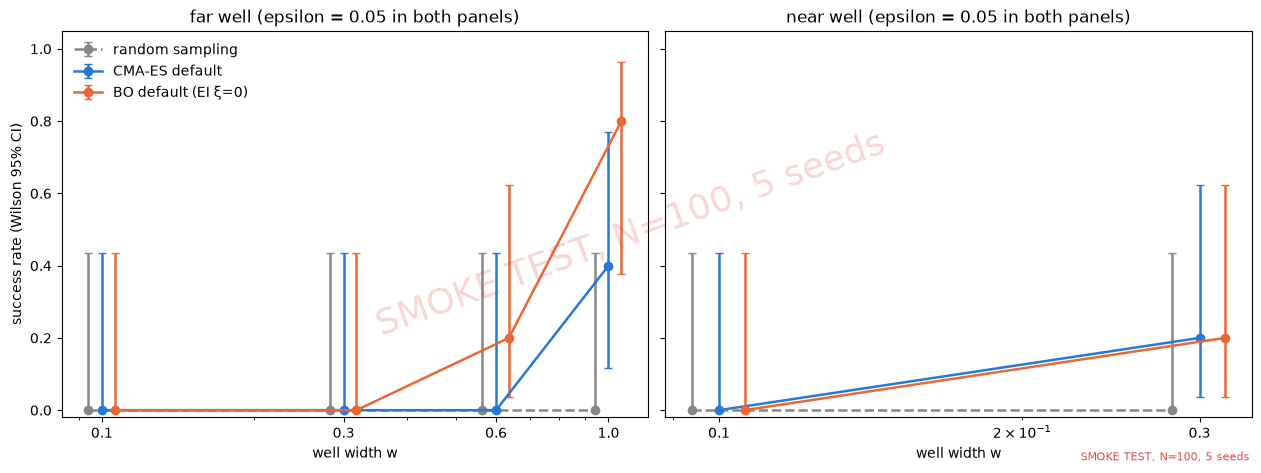

*Only CMA3 (CMA-ES) is pre-registered for Exp 8; there is none for BO (see `docs/predictions_addendum.md`). Near-well cells at w = 0.6 and w = 1.0 are excluded because the near well's basin merges with the decoy there (`docs/pilot_log.md`). Random sampling is the reference at each w.*

In [23]:
report.show_predictions(['CMA3', 'BO11', 'BO12'])
report.experiment_card("exp8_baseline", M)

*Full run: N = 300, 50 seeds per cell, $\varepsilon = 0.05$. Baseline lines use seeds 1000-1049; the best-variant lines (CMA-ES `cma_sig1`, BO `bo_cap1`, chosen by the extended rule in `docs/pilot_log.md`) and their defaults re-run on fresh seeds 2000-2049 only. Set `FAST = False` to see the figure.*

**Result (successes out of 50).**

| Far well, $w$ | 0.1 | 0.3 | 0.6 | 1.0 |
|---|---|---|---|---|
| random (seeds 1000-1049) | 0 | 2 | 3 | 10 |
| CMA-ES default (1000-1049) | 0 | 0 | 2 | 30 |
| BO default (1000-1049) | 0 | 5 | 23 | 45 |
| CMA-ES default (fresh) | 0 | 0 | 10 | 35 |
| `cma_sig1` (fresh) | 1 | 4 | 9 | 30 |
| BO default (fresh) | 0 | 1 | 10 | 39 |
| `bo_cap1` (fresh) | 1 | 44 | 50 | 50 |

| Near well, $w$ | 0.1 | 0.3 |
|---|---|---|
| random (1000-1049) | 0 | 0 |
| CMA-ES default (1000-1049) / fresh | 0 / 0 | 23 / 30 |
| BO default (1000-1049) / fresh | 1 / 1 | 10 / 13 |
| `cma_sig1` (fresh) | 0 | 26 |
| `bo_cap1` (fresh) | 23 | 50 |

**Prediction checks (statuses are yours to set in `docs/scoreboard.csv`).**

- **CMA3** (default CMA-ES success at $w = 1.0$ above $w = 0.3$ with non-overlapping Wilson intervals; $w = 0.1$ not above $w = 0.3$): $w = 1.0$ is 30/50 [0.46, 0.72] and $w = 0.3$ is 0/50 [0.00, 0.07]; $w = 0.1$ is 0/50. The measurements fall on the **supported** side. Random sampling is 10/50 at $w = 1.0$, so the CMA-ES rate is above the reference there.
- **BO11** (default BO, $w = 1.0$ above $w = 0.3$, Newcombe interval wholly above zero): 45/50 against 5/50, difference +0.80 [+0.64, +0.88]. **Supported.**
- **BO12** (the cap-1 gain over default BO, on fresh seeds, is larger at $w = 0.3$ than at $w = 0.1$ and at $w = 1.0$): gains are +0.02 [-0.05, +0.10] at $w = 0.1$, +0.86 [+0.71, +0.93] at $w = 0.3$, +0.80 [+0.65, +0.89] at $w = 0.6$ and +0.22 [+0.10, +0.35] at $w = 1.0$. The written condition is met on the point estimates, so it falls on the **supported** side. The gain at $w = 0.6$ is almost as large as at $w = 0.3$ (intervals overlap), so "largest at an intermediate width" describes a plateau over 0.3 to 0.6, not a peak at 0.3.

**Other measured facts.** Tuned BO is 44/50 at $w = 0.3$, 50/50 at $w \ge 0.6$ and 50/50 on the near well at $w = 0.3$; default BO and both CMA-ES settings are far below it there. `cma_sig1` is within noise of `cma_default` at every width (its best cell, 4/50 against 0/50 at far $w = 0.3$, has overlapping intervals). At the narrowest well ($w = 0.1$) nothing succeeds from the far start (at most 1/50), but `bo_cap1` reaches 23/50 from the near start. On the near well at $w = 0.3$, default CMA-ES (23/50 and 30/50) beats default BO (10/50 and 13/50), while on the far well default BO is at or above default CMA-ES at $w \ge 0.6$.

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* success needs the search to put a point within about 0.05 of the well centre, and a wider well makes that easier for every method (a larger target for the initial design or early samples). Wider wells also move $\sigma_0 / w$ toward 1 for CMA-ES, as CMA3 states; CMA5's reversed order at wide $w$ (Exp 3 follow-up) is a reminder that the effective ratio is capped by the `cma` library.
- *Hypothesis:* the cap-1 gain is a fitting effect (Exp 6): with the cap, the surrogate keeps a lengthscale on the scale of the well, so the acquisition keeps probing small features. The gain disappearing at $w = 0.1$ and shrinking at $w = 1.0$ fits that picture (a cap of 1 is too long for a well of width 0.1; default BO already succeeds at $w = 1.0$), but the width sweep does not test the mechanism.

**Caveat:**

- The best-variant selection rule was extended after Exps 4-7 were seen (logged deviation in `docs/pilot_log.md`). `bo_cap1` is a setting that suits this landscape's well width; the result shows that BO's outcome depends strongly on one fitting setting, not that BO beats CMA-ES in general, because only $\sigma_0$ (and $\lambda$, restarts) was varied for CMA-ES. `cma_sig1` was chosen on 1/50 successes, so it is a mechanical pick.
- Seed-set differences are large for some default cells (BO default at far $w = 0.6$: 23/50 on seeds 1000-1049, 10/50 on fresh seeds; CMA-ES default at the same cell 2/50 and 10/50). Both sets were pre-specified and both are reported; no explanation is offered. Cells that differ by a few runs out of 50 should not be ranked.
- One landscape family at $d = 2$, one $\varepsilon$, and BO runs reproducible only in distribution.

### Exp 9: unimodal control (sphere)

Produce results: `python run_experiments.py --full --exp exp9 --method cmaes && python run_experiments.py --full --exp exp9 --method bo --seeds 20 && python run_experiments.py --aggregate`

Sphere, $d = 2$, N = 300. Arms (rule in `docs/pilot_log.md`): CMA-ES default, $\lambda = 12$, $\lambda = 24$ and the best variant `cma_sig1` on seeds 1000-1049; BO best (`bo_cap1`) and worst (`bo_noise1`) on seeds 1000-1019. `bo_default` was added on 2026-11-02 at the user's request, after the first sphere runs and outside the written rule, to see whether the cap costs anything on a smooth function; it uses the same seeds.

In [22]:
report.show_predictions(['H5'])
report.experiment_card("exp9", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H5 | Larger lambda gives no benefit, and a small cost, on a unimodal control | Sphere regret equal or worse | Sphere benefits too (suspect an extra-samples effect) |

> **Not configured yet: Exp 7: unimodal control.** Its settings depend on the Exps 1-5 results and are added to `code/configs.py` by the rule in `docs/direction.md`.

*Full run: N = 300; CMA-ES 50 seeds (1000-1049), BO 20 seeds (1000-1019). Set `FAST = False` to see the figure. The right panel is the final regret at N = 300 per setting (median and quartiles); the left panel is regret against evaluation.*

**Result.** Final regret at N = 300 (median [quartiles]):

| setting | seeds | final regret | regret at evaluation 100 (median) |
|---|---|---|---|
| CMA-ES default ($\lambda = 6$) | 50 | 1.6e-10 [2.4e-11, 7.5e-10] | 1.1e-3 |
| CMA-ES $\lambda = 12$ | 50 | 9.8e-8 [4.2e-8, 2.4e-7] | 8.2e-3 |
| CMA-ES $\lambda = 24$ | 50 | 6.0e-5 [1.8e-5, 1.9e-4] | 8.0e-2 |
| CMA-ES `cma_sig1` | 50 | 9.8e-11 [2.1e-11, 3.0e-10] | 6.6e-4 |
| BO default (`bo_default`) | 20 | 7.9e-7 [3.3e-7, 5.0e-6] | 1.2e-6 |
| BO `bo_cap1` | 20 | 4.3e-6 [1.6e-6, 7.1e-6] | 8.9e-4 |
| BO `bo_noise1` | 20 | 2.9e-2 [2.9e-4, 0.36] | 6.8e-2 |

**H5** (larger $\lambda$ gives no benefit, and a small cost, on a unimodal control; supported if regret is equal or worse): final regret rises with $\lambda$ by orders of magnitude (1.6e-10, 9.8e-8, 6.0e-5) and the quartile ranges do not overlap. The measurements fall on the **supported** side. The status in `docs/scoreboard.csv` is yours.

**Other measured facts.** `cma_sig1` matches the default (9.8e-11 against 1.6e-10). Default BO reaches about 1e-6 within the first 20-odd evaluations, whereas CMA-ES passes that level only around evaluation 200 and ends far lower (1e-10 against 8e-7). `bo_cap1` ends close to default BO (4.3e-6 against 7.9e-7, quartile ranges overlapping at 20 seeds) but is about 1000 times slower at evaluation 100 (8.9e-4 against 1.2e-6). `bo_noise1` is much worse (2.9e-2).

**Explanation** (hypotheses, not tested here):

- *Hypothesis:* with N fixed, a larger $\lambda$ means fewer generations, so on a smooth bowl, where one sample already points the right way, the extra samples per generation buy nothing and the run ends less converged.
- *Hypothesis:* a lengthscale cap of 1 limits how far the GP can extrapolate across the bowl (width about 10), so early progress is slower; the default fit can use a long lengthscale and models the bowl at once. This is the mirror of why the cap helps on the primary landscape (Exp 6), where a long lengthscale smooths over the narrow well.

**Caveat:** a control, not a headline. It checks that $\lambda$'s effect on the primary landscape is not a generic extra-samples effect, and that the cap is a trade-off and not a free gain. BO has 20 seeds, so its end-of-run differences are uncertain; the evaluation-100 gap is large enough to trust. The BO and CMA-ES arms differ in seed count and CMA-ES has no matched default-BO comparison at equal seeds in the figure; `bo_default` was added after the first runs (logged above).

### Exp 10: validation on Rastrigin (funnel) and Schwefel (deceptive)

Produce results: `to be added to `code/configs.py` once Exps 1-7 choose the best and worst settings`

Figures when configured: success rate per function (separate panels) and the $\lambda$ gain (success-rate difference with a Newcombe interval, unpaired so conservative).

In [24]:
report.show_predictions(['H6', 'M3', 'BO5'])
report.experiment_card("exp10", M)

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H6 | Lambda helps more on a funnel landscape (Rastrigin) than on a deceptive one (Schwefel) | Larger gain on Rastrigin | Same gain on both |
| M3 | Selection averaging (larger mu_eff following the global trend) is the mechanism on Rastrigin, not on the needle landscape | On Rastrigin the lambda gain comes with the mean moving steadily toward the origin across generations | Rastrigin gain also explained only by early samples |
| BO5 | The spread between BO's best and worst settings (from Exps 4 and 5) is larger on Rastrigin (global funnel a GP can learn) than on Schwefel (deceptive: the best basin is far from its neighbours). This mirrors H6 for CMA-ES lambda | Larger best-minus-worst gap on Rastrigin than on Schwefel | Same or larger gap on Schwefel |

> **Not configured yet: Exp 9: validation (Rastrigin, Schwefel).** Its settings depend on the Exps 1-5 results and are added to `code/configs.py` by the rule in `docs/direction.md`.

**Result (with CI and effect size):** *To fill in after the full run.*

**Explanation** (untested explanations are labelled *hypothesis*): *To fill in after the full run.*

**Caveat:** *To fill in after the full run.*

*Next: every pre-registered prediction in one table, with its status.*

## 6. Prediction scoreboard

Every prediction in `docs/predictions.md`, including any later amendments. **Statuses live in `docs/scoreboard.csv` and are changed by hand, never by code**; the default is "not yet run". A prediction that is contradicted, with the diagnostics that explain it, shows more understanding than a clean confirmation.

In [25]:
report.scoreboard()

ID,Prediction,Supported by,Contradicted by,Status,note
H1,Default CMA-ES gets stuck in a decoy basin,"Low success, early sigma collapse, best point outside the global basin","High success, or sigma stays large",not yet run,
H2,"Larger lambda raises success, with a sweet spot at fixed N","Success vs lambda rises, then plateaus or falls","Monotone decline, or no change",not yet run,
H3,Restarts beat a larger lambda at equal total budget,Higher success at the same N,Equal or lower success,not yet run,
H4,BO finds the narrow basin at low d only if it explores enough,Success rises with xi or beta,Insensitive to xi and beta,not yet run,
H5,"Larger lambda gives no benefit, and a small cost, on a unimodal control",Sphere regret equal or worse,Sphere benefits too (suspect an extra-samples effect),not yet run,
H6,Lambda helps more on a funnel landscape (Rastrigin) than on a deceptive one (Schwefel),Larger gain on Rastrigin,Same gain on both,not yet run,
M1,"On the needle (primary) landscape, larger lambda helps only through extra early samples: the bowl slopes toward the decoy, so there is no global trend for selection averaging to follow",Any lambda gain is explained by the chance that a first-generation sample lands in the global basin (best point found in an early generation; gain tracks number of early samples),Successful large-lambda runs find the well in later generations after the mean has moved toward it,not yet run,
M2,"On the needle landscape, restarts act like random search: each restart succeeds roughly when its fresh start (x0, sigma0) lands near the well",Success rate of IPOP/BIPOP close to what independent restarts from uniform x0 predict; successful restart index is spread out rather than concentrated on large-lambda restarts,Success concentrated in large-lambda restarts beyond what the restart count explains,not yet run,
M3,"Selection averaging (larger mu_eff following the global trend) is the mechanism on Rastrigin, not on the needle landscape",On Rastrigin the lambda gain comes with the mean moving steadily toward the origin across generations,Rastrigin gain also explained only by early samples,not yet run,
BO1,"(post hoc, from Exp 0) Default BO fails at discovery, not refinement: it rarely samples the well, and while it has not sampled it the fitted lengthscale sits far above w",Runs with no well sample fail; runs that sampled the well reach epsilon; lengthscale before the first well sample is many times w,"Runs that sampled the well still fail, or the pre-discovery lengthscale is comparable to w",not yet run,nan


*Next: what the findings recommend, and how far they can be trusted.*

## 7. Verdict and limitations

**Use X when Y:** *to fill in after the full run.*

**Limitations.**

- **Low dimension:** the main setting is d = 2; the d = 5 check, if done, is one case.
- **Finite seeds:** 50 seeds gives a Wilson half-width of about 14% at a success rate near 0.5, so some differences will not be resolvable. A claim needs separated intervals; otherwise write "not distinguishable at this seed count".
- **One primary custom landscape**, plus two standard validation functions. A finding on the needle landscape need not transfer.
- **Regret needs a known minimum**, so success is defined only on benchmark functions, and $\varepsilon$ is a modelling choice (chosen from random sampling only).
- **Untested mechanisms are hypotheses.** Sigma collapse, lengthscale smoothing and selection averaging are explanations to be tested, not established facts.
- **Reproducibility:** A seed fixes the initial design and random streams. CMA-ES and random sampling reproduce exactly; BO reproduces in distribution, because floating-point differences compound through the model-fitting loop. Paired comparisons are paired on starting conditions only.
- **Frozen settings:** BO lengthscale bounds, CMA-ES start and restart triggers were fixed before the big runs; other choices could change the picture.